<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h1 dir="rtl" align="right">تحلیل تقلب در تراکنش‌های کارت اعتباری</h1>
<h3 dir="rtl" align="right">پروژه نهایی درس تحلیل داده (Data Analysis)</h3>
<h2 dir="rtl" align="right">معرفی پروژه</h2>
<p dir="rtl" align="right">هدف این پروژه بررسی تراکنش‌های کارت اعتباری و پیدا کردن الگوهایی است که تراکنش‌های <strong>تقلبی</strong> را از تراکنش‌های <strong>عادی</strong> جدا می‌کند. مثلاً: تقلب بیشتر در چه ساعتی رخ می‌دهد؟ در کدام دسته‌های خرید؟ آیا سن یا جنسیت مشتری اثری دارد؟</p>
<p dir="rtl" align="right"><strong>دیتاست:</strong> Credit Card Transactions Fraud Detection Dataset از سایت Kaggle. این داده <strong>شبیه‌سازی‌شده</strong> است، یعنی مشتری‌ها، نام‌ها، آدرس‌ها و شماره کارت‌ها ساختگی‌اند، ولی ساختارش مثل تراکنش‌های واقعی است.</p>
<p dir="rtl" align="right"><strong>ساختار دیتاست:</strong> دو فایل جدا با ستون‌های کاملاً یکسان:</p>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">فایل</th>
<th align="right">نقش</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right"><code dir="ltr">fraudTrain.csv</code></td>
<td align="right">بخش اول داده</td>
</tr>
<tr>
<td align="right"><code dir="ltr">fraudTest.csv</code></td>
<td align="right">بخش دوم داده</td>
</tr>
</tbody>
</table>
<p dir="rtl" align="right">هر دو فایل را به هم می‌چسبانیم و کل داده (حدود 1.85 میلیون تراکنش) را یک‌جا تحلیل می‌کنیم.</p>
<p dir="rtl" align="right"><strong>ستون هدف:</strong> <code dir="ltr">is_fraud</code> (مقدار 1 یعنی تقلب و مقدار 0 یعنی تراکنش عادی).</p>
<h2 dir="rtl" align="right">فهرست مطالب</h2>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">بخش</th>
<th align="right">محتوا</th>
<th align="right">شماره قسمت‌ها</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right">اول</td>
<td align="right">آماده‌سازی داده: کتابخانه‌ها، خواندن داده، شناخت اولیه، بهینه‌سازی نوع داده‌ها، کیفیت داده، ساخت ستون‌های جدید</td>
<td align="right">1 تا 7</td>
</tr>
<tr>
<td align="right">دوم</td>
<td align="right">تحلیل تک‌متغیره: بررسی تک‌تک ستون‌ها</td>
<td align="right">8 تا 24</td>
</tr>
<tr>
<td align="right">سوم</td>
<td align="right">تحلیل دومتغیره: رابطه ستون‌ها با تقلب و ماتریس همبستگی</td>
<td align="right">25 تا 34</td>
</tr>
<tr>
<td align="right">چهارم</td>
<td align="right">تحلیل چندمتغیره: بررسی هم‌زمان چند ستون</td>
<td align="right">35 تا 37</td>
</tr>
<tr>
<td align="right">پنجم</td>
<td align="right">آزمون‌های آماری: Mann-Whitney و Kolmogorov-Smirnov</td>
<td align="right">38 تا 41</td>
</tr>
<tr>
<td align="right">ششم</td>
<td align="right">نتیجه‌گیری نهایی</td>
<td align="right">42</td>
</tr>
</tbody>
</table>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h2 dir="rtl" align="right">بخش اول: آماده‌سازی داده</h2>
<p dir="rtl" align="right">در این بخش داده را می‌خوانیم، نوع ستون‌ها را بهینه می‌کنیم، ستون‌های غیرضروری را حذف می‌کنیم، کیفیت داده را بررسی می‌کنیم و ستون‌های جدید می‌سازیم تا داده برای تحلیل آماده شود.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">1. وارد کردن کتابخانه‌ها</h3>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">کتابخانه</th>
<th align="right">کاربرد</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right"><code dir="ltr">pandas</code></td>
<td align="right">خواندن فایل‌ها، ساخت DataFrame و همه عملیات تحلیلی</td>
</tr>
<tr>
<td align="right"><code dir="ltr">numpy</code></td>
<td align="right">نوع‌های عددی کوچک مثل <code dir="ltr">np.float32</code> و <code dir="ltr">np.int32</code> که در بهینه‌سازی رم استفاده می‌کنیم</td>
</tr>

</tbody>
</table>
</div>

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import mannwhitneyu, ks_2samp

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">2. خواندن داده‌ها</h3>
<p dir="rtl" align="right">هر دو فایل را با <code dir="ltr">pd.read_csv</code> به‌صورت DataFrame می‌خوانیم.</p>
<p dir="rtl" align="right"><strong><code dir="ltr">index_col=0</code></strong>: فایل‌های این دیتاست یک ستون اول بدون نام دارند که فقط شماره ردیف است (0، 1، 2، ...). این گزینه یعنی «ستون شماره 0 را به‌عنوان index بخوان، نه به‌عنوان یک ستون داده». بدون آن، یک ستون اضافه و بی‌فایده به اسم <code dir="ltr">Unnamed: 0</code> وارد داده می‌شد.</p>
<p dir="rtl" align="right"><strong>توجه:</strong> در این مرحله ستون‌های زمانی (<code dir="ltr">trans_date_trans_time</code> و <code dir="ltr">dob</code>) هنوز متن (str) خوانده می‌شوند. تبدیلشان به تاریخ در بخش 4 انجام می‌شود.</p>
</div>

In [2]:
train = pd.read_csv("fraudTrain.csv", index_col=0)
test = pd.read_csv("fraudTest.csv", index_col=0)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">چسباندن دو DataFrame به هم</h4>
<p dir="rtl" align="right">چون ستون‌های <code dir="ltr">train</code> و <code dir="ltr">test</code> یکی است، با <code dir="ltr">pd.concat</code> آن‌ها را <strong>زیر هم</strong> می‌چسبانیم. ترتیب مهم است: اول <code dir="ltr">train</code> و بعد <code dir="ltr">test</code>.</p>
<p dir="rtl" align="right"><strong><code dir="ltr">ignore_index=True</code></strong>: وقتی دو DataFrame را زیر هم می‌چسبانیم، هر کدام شماره ردیف خودش را با خودش می‌آورد؛ یعنی index بخش دوم دوباره از 0 شروع می‌شود و شماره‌های تکراری داریم. با این گزینه pandas index‌های قبلی را دور می‌اندازد و از اول تا آخر دوباره شماره‌گذاری می‌کند (0 تا آخر).</p>
</div>

In [3]:
df = pd.concat([train, test], ignore_index=True)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">3. شناخت اولیه داده</h3>
<p dir="rtl" align="right">سه کار انجام می‌دهیم:</p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>بازه زمانی:</strong> اولین و آخرین تراکنش با <code dir="ltr">min()</code> و <code dir="ltr">max()</code>. نکته: ستون هنوز متن است و متن‌ها به ترتیب الفبایی مقایسه می‌شوند، ولی چون فرمت تاریخ به شکل <code dir="ltr">سال-ماه-روز ساعت:دقیقه:ثانیه</code> است، ترتیب الفبایی با ترتیب زمانی یکی است و نتیجه درست است.</li>
<li dir="rtl" align="right"><strong><code dir="ltr">df.head()</code>:</strong> پنج ردیف اول، برای دیدن شکل داده.</li>
<li dir="rtl" align="right"><strong><code dir="ltr">df.info()</code>:</strong> تعداد ردیف و ستون، نوع هر ستون و مقدار رم مصرفی.</li>
</ul>
<p dir="rtl" align="right">بازه زمانی از <strong>2019-01-01 00:00:18</strong> تا <strong>2020-12-31 23:59:34</strong> است، یعنی دو سال کامل.</p>
</div>

In [4]:
df["trans_date_trans_time"].min(), df["trans_date_trans_time"].max()

('2019-01-01 00:00:18', '2020-12-31 23:59:34')

In [5]:
df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 22 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   trans_date_trans_time  str    
 1   cc_num                 int64  
 2   merchant               str    
 3   category               str    
 4   amt                    float64
 5   first                  str    
 6   last                   str    
 7   gender                 str    
 8   street                 str    
 9   city                   str    
 10  state                  str    
 11  zip                    int64  
 12  lat                    float64
 13  long                   float64
 14  city_pop               int64  
 15  job                    str    
 16  dob                    str    
 17  trans_num              str    
 18  unix_time              int64  
 19  merch_lat              float64
 20  merch_long             float64
 21  is_fraud               int64  
dtypes: float64(5), int64(5), str(

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">نتیجه شناخت اولیه</h4>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>1,852,394 ردیف</strong> و <strong>22 ستون</strong> داریم.</li>
<li dir="rtl" align="right">نوع ستون‌ها: 12 ستون متنی (<code dir="ltr">str</code>)، 5 ستون <code dir="ltr">float64</code> و 5 ستون <code dir="ltr">int64</code>.</li>
<li dir="rtl" align="right">رم مصرفی <strong>595.3 مگابایت</strong> است. در بخش بعد آن را به‌شدت کم می‌کنیم.</li>
<li dir="rtl" align="right">دو ستون زمانی (<code dir="ltr">trans_date_trans_time</code> و <code dir="ltr">dob</code>) هنوز متن‌اند.</li>
<li dir="rtl" align="right">بسیاری از ستون‌های متنی (مثل <code dir="ltr">gender</code>، <code dir="ltr">state</code>، <code dir="ltr">category</code>) مقدارهای تکراری زیادی دارند و برای رم گران‌اند.</li>
<li dir="rtl" align="right"><code dir="ltr">cc_num</code> از نوع <code dir="ltr">int64</code> است ولی در واقع شناسه مشتری است، نه عددی که با آن محاسبه کنیم.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">4. بهینه‌سازی نوع داده‌ها و حذف ستون‌های غیرضروری</h3>
<p dir="rtl" align="right">pandas برای ستون‌های متنی و عددی به‌طور پیش‌فرض سنگین‌ترین نوع را انتخاب می‌کند. با انتخاب نوع مناسب، همان داده را با رم خیلی کمتر نگه می‌داریم و عملیات (مثل <code dir="ltr">groupby</code>) هم سریع‌تر می‌شود.</p>
<p dir="rtl" align="right"><strong>روش کار برای هر ستون:</strong> اول بررسی می‌کنیم (<code dir="ltr">value_counts</code>، <code dir="ltr">nunique</code>، <code dir="ltr">min</code>/<code dir="ltr">max</code>)، بعد نوع مناسب را انتخاب می‌کنیم، بعد تبدیل می‌کنیم.</p>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">نوع ستون</th>
<th align="right">تصمیم</th>
<th align="right">دلیل</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right">متن با مقدارهای تکراری زیاد (<code dir="ltr">cc_num</code>، <code dir="ltr">merchant</code>، <code dir="ltr">category</code>، <code dir="ltr">gender</code>، <code dir="ltr">city</code>، <code dir="ltr">state</code>، <code dir="ltr">job</code>)</td>
<td align="right"><code dir="ltr">category</code></td>
<td align="right">مقدارهای یکتا فقط یک بار ذخیره می‌شوند و هر ردیف فقط یک کد کوچک دارد</td>
</tr>
<tr>
<td align="right">اعشاری (<code dir="ltr">amt</code>، <code dir="ltr">lat</code>، <code dir="ltr">long</code>، <code dir="ltr">merch_lat</code>، <code dir="ltr">merch_long</code>)</td>
<td align="right"><code dir="ltr">float32</code></td>
<td align="right">دقت حدود 7 رقم برای تحلیل کافی است و رم نصف <code dir="ltr">float64</code> است</td>
</tr>
<tr>
<td align="right">صحیح (<code dir="ltr">zip</code>، <code dir="ltr">city_pop</code>)</td>
<td align="right"><code dir="ltr">int32</code></td>
<td align="right">بیشترین مقدار هر دو خیلی کمتر از سقف <code dir="ltr">int32</code> (حدود 2.1 میلیارد) است</td>
</tr>
<tr>
<td align="right">برچسب 0/1 (<code dir="ltr">is_fraud</code>)</td>
<td align="right"><code dir="ltr">int8</code></td>
<td align="right">فقط دو مقدار دارد</td>
</tr>
<tr>
<td align="right">تاریخ (<code dir="ltr">trans_date_trans_time</code>، <code dir="ltr">dob</code>)</td>
<td align="right"><code dir="ltr">datetime</code></td>
<td align="right">برای استفاده از <code dir="ltr">.dt</code> و محاسبه تفاضل تاریخ‌ها</td>
</tr>
<tr>
<td align="right">ستون‌های بی‌فایده (<code dir="ltr">trans_num</code>، <code dir="ltr">unix_time</code>، <code dir="ltr">first</code>، <code dir="ltr">last</code>، <code dir="ltr">street</code>)</td>
<td align="right">حذف</td>
<td align="right">در ادامه برای هر کدام دلیل می‌آوریم</td>
</tr>
</tbody>
</table>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.1 زمان تراکنش (<code dir="ltr">trans_date_trans_time</code>)</h4>
<p dir="rtl" align="right">با <code dir="ltr">pd.to_datetime</code> این ستون را از متن به نوع تاریخ‌وزمان (<code dir="ltr">datetime64</code>) تبدیل می‌کنیم.</p>
<p dir="rtl" align="right"><strong>دلیل:</strong> روی ستون متنی نمی‌شود از <code dir="ltr">.dt.hour</code>، <code dir="ltr">.dt.day_name()</code> و <code dir="ltr">.dt.month</code> استفاده کرد و نمی‌شود دو تاریخ را از هم کم کرد. هر دو کار در بخش 6 لازم می‌شود (ساعت، روز هفته، ماه، سن).</p>
</div>

In [7]:
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.2 شماره کارت (<code dir="ltr">cc_num</code>)</h4>
<p dir="rtl" align="right">مراحل: اول <code dir="ltr">value_counts</code> برای دیدن تعداد تراکنش هر کارت، بعد تبدیل به <code dir="ltr">category</code>، بعد <code dir="ltr">nunique</code> برای شمردن کارت‌های یکتا.</p>
<p dir="rtl" align="right"><strong>نتیجه:</strong> <strong>999 شماره کارت یکتا</strong> داریم. هر کارت بین 6 تا 4,392 تراکنش دارد. چون هر شماره کارت متعلق به یک مشتری است، <code dir="ltr">cc_num</code> را به‌عنوان <strong>شناسه مشتری</strong> استفاده می‌کنیم (مثلاً برای اینکه ببینیم هر مشتری چند تراکنش دارد). شماره‌ها ساختگی‌اند.</p>
<p dir="rtl" align="right"><strong>چرا <code dir="ltr">category</code> و نه یک نوع صحیح کوچک؟</strong> این اعداد خیلی بزرگ‌اند (تا چندین کوادریلیون) و فقط در <code dir="ltr">int64</code> جا می‌شوند. ولی چون فقط 999 مقدار یکتا دارند، <code dir="ltr">category</code> هم رم کمتری می‌گیرد و هم <code dir="ltr">groupby</code> روی آن سریع‌تر است.</p>
<p dir="rtl" align="right"><strong>نکته مهم:</strong> <code dir="ltr">cc_num</code> یک شناسه است نه یک مقدار عددی؛ میانگین یا همبستگی گرفتن از آن بی‌معناست. تبدیل به <code dir="ltr">category</code> جلوی این اشتباه را هم می‌گیرد، چون ستون‌های <code dir="ltr">category</code> در <code dir="ltr">corr()</code> وارد نمی‌شوند.</p>
</div>

In [8]:
print(df["cc_num"].value_counts())

cc_num
30270432095985         4392
6538441737335434       4392
4642255475285942       4386
4364010865167176       4386
6538891242532018       4386
                       ... 
6577777028615915          7
4225628813173670          7
180097223252063           7
4352307151555405069       7
4295296907373             6
Name: count, Length: 999, dtype: int64


In [9]:
df["cc_num"] = df["cc_num"].astype("category")

In [10]:
df["cc_num"].nunique()

999

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.3 فروشنده (<code dir="ltr">merchant</code>)</h4>
<p dir="rtl" align="right">فقط <strong>693 مقدار یکتا</strong> در 1.85 میلیون ردیف داریم، پس بهترین انتخاب <code dir="ltr">category</code> است. پرتکرارترین فروشنده <code dir="ltr">fraud_Kilback LLC</code> با 6,262 تراکنش است.</p>
<p dir="rtl" align="right"><strong>نکته:</strong> در نمونه‌هایی که دیدیم، اسم همه فروشنده‌ها با پیشوند <code dir="ltr">fraud_</code> شروع می‌شود. این پیشوند بخشی از نام داده در دیتاست است و به معنی تقلبی بودن فروشنده نیست. فعلاً دست‌نخورده نگهش داشته‌ایم و اگر در نمودارها اسم‌ها شلوغ شد، می‌شود آن را حذف کرد.</p>
</div>

In [11]:
print(df["merchant"].value_counts())

merchant
fraud_Kilback LLC                        6262
fraud_Cormier LLC                        5246
fraud_Schumm PLC                         5195
fraud_Kuhn LLC                           5031
fraud_Boyer PLC                          4999
                                         ... 
fraud_Douglas, DuBuque and McKenzie      1101
fraud_Treutel-King                       1098
fraud_Satterfield-Lowe                   1095
fraud_Hahn, Douglas and Schowalter       1091
fraud_Ritchie, Bradtke and Stiedemann    1090
Name: count, Length: 693, dtype: int64


In [12]:
df["merchant"] = df["merchant"].astype("category")

In [13]:
df["merchant"].nunique()

693

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.4 دسته خرید (<code dir="ltr">category</code>)</h4>
<p dir="rtl" align="right"><strong>14 دسته</strong> داریم. بیشترین تراکنش‌ها به ترتیب مال <code dir="ltr">gas_transport</code> (188,029)، <code dir="ltr">grocery_pos</code> (176,191) و <code dir="ltr">home</code> (175,460) است و کم‌ترین مال <code dir="ltr">travel</code> (57,956). چون فقط 14 مقدار یکتا دارد، به <code dir="ltr">category</code> تبدیل می‌شود.</p>
</div>

In [14]:
print(df["category"].value_counts())

category
gas_transport     188029
grocery_pos       176191
home              175460
shopping_pos      166463
kids_pets         161727
shopping_net      139322
entertainment     134118
food_dining       130729
personal_care     130085
health_fitness    122553
misc_pos          114229
misc_net           90654
grocery_net        64878
travel             57956
Name: count, dtype: int64


In [15]:
df["category"] = df["category"].astype("category")

In [16]:
df["category"].nunique()

14

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.5 مبلغ تراکنش (<code dir="ltr">amt</code>)</h4>
<p dir="rtl" align="right">کمترین مبلغ <strong>1.0</strong> و بیشترین <strong>28,948.9</strong> دلار است. هیچ مبلغ صفر یا منفی نداریم. <code dir="ltr">float32</code> برای این بازه دقت کافی دارد.</p>
<p dir="rtl" align="right"><strong>نکته برای تحلیل‌های بعدی:</strong> فاصله خیلی زیاد بین مبلغ‌های معمولی و بیشترین مبلغ نشان می‌دهد توزیع این ستون چولگی دارد. جزئیاتش را در تحلیل تک‌متغیره بررسی می‌کنیم.</p>
</div>

In [17]:
df["amt"].min(), df["amt"].max()

(np.float64(1.0), np.float64(28948.9))

In [18]:
df["amt"] = df["amt"].astype(np.float32)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.6 جنسیت (<code dir="ltr">gender</code>)</h4>
<p dir="rtl" align="right">دو مقدار دارد: <code dir="ltr">F</code> با 1,014,749 تراکنش (حدود 54.8٪) و <code dir="ltr">M</code> با 837,645 تراکنش (حدود 45.2٪). به <code dir="ltr">category</code> تبدیل می‌شود.</p>
</div>

In [19]:
df["gender"].value_counts()

gender
F    1014749
M     837645
Name: count, dtype: int64

In [20]:
df["gender"] = df["gender"].astype("category")

In [21]:
df["gender"].nunique()

2

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.7 شهر (<code dir="ltr">city</code>)</h4>
<p dir="rtl" align="right"><strong>906 شهر یکتا</strong> داریم. بیشترین تراکنش مال <code dir="ltr">Birmingham</code> با 8,040 مورد است. به <code dir="ltr">category</code> تبدیل می‌شود.</p>
</div>

In [22]:
print(df["city"].value_counts())

city
Birmingham     8040
San Antonio    7312
Utica          7309
Phoenix        7297
Meridian       7289
               ... 
Norfolk           7
Karns City        7
Bruce             7
Streator          7
Wever             6
Name: count, Length: 906, dtype: int64


In [23]:
df["city"] = df["city"].astype("category")

In [24]:
df["city"].nunique()

906

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.8 ایالت (<code dir="ltr">state</code>)</h4>
<p dir="rtl" align="right"><strong>51 مقدار یکتا</strong> داریم. بیشترین تراکنش‌ها: <code dir="ltr">TX</code> (135,269)، <code dir="ltr">NY</code> (119,419) و <code dir="ltr">PA</code> (114,173). به <code dir="ltr">category</code> تبدیل می‌شود.</p>
</div>

In [25]:
print(df["state"].value_counts())

state
TX    135269
NY    119419
PA    114173
CA     80495
OH     66627
MI     65825
IL     62212
FL     60775
AL     58521
MO     54904
MN     45433
AR     44611
NC     43134
VA     41756
WI     41738
SC     41731
KY     40981
IN     39539
IA     38804
OK     38050
MD     37345
GA     37340
WV     36529
NJ     35131
NE     34425
KS     32939
MS     30021
LA     29953
WY     27776
WA     27040
OR     26408
TN     24913
ME     23433
NM     23427
ND     21183
CO     19766
SD     17574
MA     17562
VT     16812
MT     16806
AZ     15362
UT     15357
NH     11727
CT     10979
NV      8058
ID      8035
DC      5130
HI      3649
AK      2963
RI       745
DE         9
Name: count, dtype: int64


In [26]:
df["state"] = df["state"].astype("category")

In [27]:
df["state"].nunique()

51

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.9 کد پستی (<code dir="ltr">zip</code>)</h4>
<p dir="rtl" align="right">کمترین مقدار 1,257 و بیشترین 99,921 است، پس <code dir="ltr">int32</code> کافی است. دستور <code dir="ltr">count()</code> فقط مقدارهای غیرگمشده را می‌شمارد؛ چون برابر کل ردیف‌هاست (1,852,394)، این ستون <strong>مقدار گمشده ندارد</strong>.</p>
<p dir="rtl" align="right"><strong>نکته:</strong> کد پستی عددی است ولی معنای عددی ندارد (میانگین کد پستی بی‌معنی است). آن را مثل یک شناسه جغرافیایی ببین.</p>
</div>

In [28]:
df["zip"].min(), df["zip"].max()

(np.int64(1257), np.int64(99921))

In [29]:
df["zip"].count()

np.int64(1852394)

In [30]:
df["zip"] = df["zip"].astype(np.int32)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.10 مختصات خانه مشتری (<code dir="ltr">lat</code> و <code dir="ltr">long</code>)</h4>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><code dir="ltr">lat</code> از 20.03 تا 66.69 و <code dir="ltr">long</code> از -165.67 تا -67.95 است. این بازه‌ها با محدوده جغرافیایی آمریکا سازگارند.</li>
<li dir="rtl" align="right">هر دو ستون مقدار گمشده ندارند (<code dir="ltr">count</code> برابر با کل ردیف‌هاست).</li>
<li dir="rtl" align="right">نوع <code dir="ltr">float32</code> (حدود 7 رقم دقت) برای مختصات کافی است.</li>
</ul>
</div>

In [31]:
df["lat"].min(), df["lat"].max()

(np.float64(20.0271), np.float64(66.6933))

In [32]:
df["lat"].count()

np.int64(1852394)

In [33]:
df["lat"] = df["lat"].astype(np.float32)

In [34]:
df["long"].min(), df["long"].max()

(np.float64(-165.6723), np.float64(-67.9503))

In [35]:
df["long"].count()

np.int64(1852394)

In [36]:
df["long"] = df["long"].astype(np.float32)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.11 جمعیت شهر (<code dir="ltr">city_pop</code>)</h4>
<p dir="rtl" align="right">از <strong>23</strong> نفر تا <strong>2,906,700</strong> نفر. یعنی هم روستای خیلی کوچک و هم شهر بزرگ در داده هست. مقدار گمشده ندارد و <code dir="ltr">int32</code> کافی است.</p>
</div>

In [37]:
df["city_pop"].min(), df["city_pop"].max()

(np.int64(23), np.int64(2906700))

In [38]:
df["city_pop"].count()

np.int64(1852394)

In [39]:
df["city_pop"] = df["city_pop"].astype(np.int32)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.12 شغل (<code dir="ltr">job</code>)</h4>
<p dir="rtl" align="right"><strong>497 شغل یکتا</strong> داریم و پرتکرارترین آن <code dir="ltr">Film/video editor</code> با 13,898 تراکنش است. به <code dir="ltr">category</code> تبدیل می‌شود.</p>
</div>

In [40]:
print(df["job"].value_counts())

job
Film/video editor             13898
Exhibition designer           13167
Surveyor, land/geomatics      12436
Naval architect               12434
Materials engineer            11711
                              ...  
Information officer               8
Engineer, water                   8
Contracting civil engineer        7
Ship broker                       7
Warehouse manager                 7
Name: count, Length: 497, dtype: int64


In [41]:
df["job"] = df["job"].astype("category")

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.13 تاریخ تولد (<code dir="ltr">dob</code>)</h4>
<p dir="rtl" align="right"><strong>984 تاریخ تولد یکتا</strong> داریم (تقریباً به تعداد مشتری‌ها). این ستون را به نوع <code dir="ltr">datetime</code> تبدیل می‌کنیم تا در بخش 6 بتوانیم <strong>سن مشتری</strong> را از تفاضل آن با زمان تراکنش حساب کنیم.</p>
</div>

In [42]:
print(df["dob"].value_counts())

dob
1977-03-23    8044
1988-09-15    6574
1981-08-29    6571
1955-05-06    5121
1960-01-13    4395
              ... 
1999-10-26       7
1964-09-17       7
1936-05-04       7
1932-05-09       7
1998-08-02       6
Name: count, Length: 984, dtype: int64


In [43]:
df["dob"] = pd.to_datetime(df["dob"])

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.14 شناسه تراکنش (<code dir="ltr">trans_num</code>): حذف</h4>
<p dir="rtl" align="right">این ستون <strong>شناسه یکتای هر تراکنش</strong> است. اول با <code dir="ltr">is_unique</code> بررسی کردیم که تکراری نباشد؛ نتیجه <code dir="ltr">True</code> شد، یعنی هر ردیف یک تراکنش مستقل است و ردیف تکراری نداریم.</p>
<p dir="rtl" align="right"><strong>چرا برای تحلیل بی‌فایده است؟</strong> چون هیچ دو ردیفی مقدار یکسان ندارند، نمی‌شود با آن گروه‌بندی کرد، نمودار کشید یا الگو پیدا کرد. مقدارش هم یک رشته تصادفی است و درباره تقلب بودن هیچ اطلاعاتی نمی‌دهد. ضمناً 1.85 میلیون رشته یکتا رم زیادی می‌گیرد و <code dir="ltr">category</code> هم کمکی نمی‌کند.</p>
<p dir="rtl" align="right"><strong>شناسه یکتا کی به درد می‌خورد؟</strong> برای پیدا کردن یک تراکنش مشخص، وصل کردن چند جدول به هم (join) و تشخیص ردیف تکراری. هیچ‌کدام در این پروژه لازم نیست، پس بعد از بررسی یکتایی، ستون را حذف می‌کنیم.</p>
</div>

In [44]:
print(df["trans_num"].is_unique)

True


In [45]:
df.drop(columns=["trans_num"], inplace=True)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.15 زمان یونیکس (<code dir="ltr">unix_time</code>): حذف</h4>
<p dir="rtl" align="right"><code dir="ltr">unix_time</code> زمان را به‌صورت یک عدد نشان می‌دهد: تعداد ثانیه‌های گذشته از 1 ژانویه 1970.</p>
<p dir="rtl" align="right"><strong>بررسی انجام‌شده:</strong> ستون را با <code dir="ltr">pd.to_datetime(..., unit="s")</code> (یعنی عدد بر حسب ثانیه) به تاریخ تبدیل کردیم و <strong>ردیف‌به‌ردیف</strong> با <code dir="ltr">trans_date_trans_time</code> مقایسه کردیم. نتیجه هر ردیف <code dir="ltr">True</code> (برابر) یا <code dir="ltr">False</code> (نابرابر) است. <code dir="ltr">mean()</code> روی این نتیجه، <strong>نسبت ردیف‌های برابر</strong> را می‌دهد.</p>
<p dir="rtl" align="right"><strong>نتیجه 0.0:</strong> یعنی هیچ ردیفی دقیقاً برابر نیست. پس این ستون کپی عین‌به‌عین ستون زمان نیست و مقدارش با آن فرق دارد.</p>
<p dir="rtl" align="right"><strong>چرا باز هم حذفش می‌کنیم؟</strong> برای هر چیزی که از زمان لازم داریم (ساعت، روز هفته، ماه، سن) از <code dir="ltr">trans_date_trans_time</code> استفاده می‌کنیم که خوانا و قابل‌استفاده است. یک عدد خام ثانیه برای تحلیل ما کاربرد اضافه‌ای ندارد و نگه داشتنش فقط رم و شلوغی اضافه می‌کند.</p>
</div>

In [46]:
(pd.to_datetime(df["unix_time"], unit="s") == df["trans_date_trans_time"]).mean()

np.float64(0.0)

In [47]:
df.drop(columns=["unix_time"], inplace=True)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.16 مختصات فروشنده (<code dir="ltr">merch_lat</code> و <code dir="ltr">merch_long</code>)</h4>
<p dir="rtl" align="right">تعداد مقدارهای یکتا: <code dir="ltr">merch_lat</code> حدود 1,754,157 و <code dir="ltr">merch_long</code> حدود 1,809,753 از 1,852,394 ردیف. یعنی تقریباً هر ردیف مقدار متفاوتی دارد و این ستون‌ها پیوسته‌اند.</p>
<p dir="rtl" align="right"><strong>نتیجه:</strong> تبدیل به <code dir="ltr">category</code> فایده‌ای ندارد (چیزی فشرده نمی‌شود)، پس مثل <code dir="ltr">lat</code> و <code dir="ltr">long</code> به <code dir="ltr">float32</code> تبدیل می‌شوند.</p>
</div>

In [48]:
print(df["merch_lat"].value_counts())

merch_lat
41.014694    4
39.545984    4
40.016559    4
40.456305    4
37.810182    4
            ..
39.946837    1
29.661049    1
46.658340    1
44.470525    1
36.210097    1
Name: count, Length: 1754157, dtype: int64


In [49]:
df["merch_lat"] = df["merch_lat"].astype(np.float32)

In [50]:
print(df["merch_long"].value_counts())

merch_long
-92.521318     4
-95.822621     4
-82.223196     4
-87.621011     4
-73.900295     4
              ..
-123.553032    1
-87.539669     1
-119.715054    1
-117.080888    1
-97.036372     1
Name: count, Length: 1809753, dtype: int64


In [51]:
df["merch_long"] = df["merch_long"].astype(np.float32)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.17 ستون هدف (<code dir="ltr">is_fraud</code>)</h4>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">تراکنش عادی (0): <strong>1,842,743</strong></li>
<li dir="rtl" align="right">تراکنش تقلبی (1): <strong>9,651</strong></li>
</ul>
<p dir="rtl" align="right">فقط دو مقدار دارد، پس <code dir="ltr">int8</code> کافی است. نسبت دقیق این دو را در بخش 5.4 بررسی می‌کنیم.</p>
</div>

In [52]:
df["is_fraud"].value_counts()

is_fraud
0    1842743
1       9651
Name: count, dtype: int64

In [53]:
df["is_fraud"] = df["is_fraud"].astype(np.int8)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">4.18 حذف نام و آدرس (<code dir="ltr">first</code>، <code dir="ltr">last</code>، <code dir="ltr">street</code>)</h4>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">ستون</th>
<th align="right">دلیل حذف</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right"><code dir="ltr">first</code> و <code dir="ltr">last</code></td>
<td align="right">نام و نام خانوادگی <strong>اطلاعات شخصی</strong> هستند. هویت مشتری را <code dir="ltr">cc_num</code> نگه می‌دارد و نام هیچ الگویی برای تقلب نمی‌سازد. ضمناً ستون متنی سنگینی هستند</td>
</tr>
<tr>
<td align="right"><code dir="ltr">street</code></td>
<td align="right">آدرس دقیق خانه هم اطلاعات شخصی است و تقریباً برای هر مشتری یکتاست، پس چیزی بیشتر از <code dir="ltr">cc_num</code> نمی‌دهد. اطلاعات مکانی مفید را <code dir="ltr">city</code>، <code dir="ltr">state</code> و <code dir="ltr">lat</code>/<code dir="ltr">long</code> پوشش می‌دهند</td>
</tr>
</tbody>
</table>
<p dir="rtl" align="right">اگر با داده واقعی کار می‌کردیم، حذف این ستون‌ها از نظر حریم خصوصی هم الزامی بود.</p>
</div>

In [54]:
df.drop(columns=["first", "last", "street"], inplace=True)

In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 17 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   trans_date_trans_time  datetime64[us]
 1   cc_num                 category      
 2   merchant               category      
 3   category               category      
 4   amt                    float32       
 5   gender                 category      
 6   city                   category      
 7   state                  category      
 8   zip                    int32         
 9   lat                    float32       
 10  long                   float32       
 11  city_pop               int32         
 12  job                    category      
 13  dob                    datetime64[us]
 14  merch_lat              float32       
 15  merch_long             float32       
 16  is_fraud               int8          
dtypes: category(7), datetime64[us](2), float32(5), int32(2), int8(1)
memory usag

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">نتیجه بهینه‌سازی</h4>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right"></th>
<th align="right">قبل</th>
<th align="right">بعد</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right">تعداد ستون‌ها</td>
<td align="right">22</td>
<td align="right">17</td>
</tr>
<tr>
<td align="right">رم مصرفی</td>
<td align="right">595.3 MB</td>
<td align="right"><strong>99.0 MB</strong> (حدود 83٪ کمتر)</td>
</tr>
</tbody>
</table>
<p dir="rtl" align="right">انواع داده بعد از بهینه‌سازی: 7 ستون <code dir="ltr">category</code>، 2 ستون <code dir="ltr">datetime64</code>، 5 ستون <code dir="ltr">float32</code>، 2 ستون <code dir="ltr">int32</code> و 1 ستون <code dir="ltr">int8</code>.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">5. بررسی کیفیت داده</h3>
<p dir="rtl" align="right">قبل از هر تحلیلی باید مطمئن شویم داده تمیز است: مقدار گمشده، ردیف تکراری و آمار کلی ستون‌ها.</p>
<h4 dir="rtl" align="right">5.1 مقدار گمشده</h4>
<p dir="rtl" align="right">با <code dir="ltr">df.isnull().sum()</code> تعداد مقدار خالی هر ستون را می‌شماریم.</p>
<p dir="rtl" align="right"><strong>نتیجه:</strong> برای همه ستون‌ها <strong>صفر</strong> است، یعنی <strong>هیچ مقدار گمشده‌ای نداریم</strong> و نیازی به پر کردن یا حذف ردیف نیست.</p>
</div>

In [56]:
print(df.isnull().sum())

trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
gender                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">5.2 ردیف تکراری</h4>
<p dir="rtl" align="right"><code dir="ltr">df.duplicated().sum()</code> تعداد ردیف‌هایی را می‌شمارد که عیناً مثل ردیف دیگری هستند.</p>
<p dir="rtl" align="right"><strong>نتیجه:</strong> صفر. <strong>هیچ ردیف تکراری‌ای نداریم.</strong></p>
</div>

In [57]:
print(df.duplicated().sum())

0


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">5.3 آمار توصیفی (<code dir="ltr">describe</code>)</h4>
<p dir="rtl" align="right">این دستور برای ستون‌های عددی و زمانی این‌ها را نشان می‌دهد: تعداد (<code dir="ltr">count</code>)، میانگین (<code dir="ltr">mean</code>)، کمترین (<code dir="ltr">min</code>)، چارک‌های 25٪ و 50٪ (میانه) و 75٪، بیشترین (<code dir="ltr">max</code>) و انحراف معیار (<code dir="ltr">std</code>). برای ستون‌های <code dir="ltr">category</code> نمایش داده نمی‌شود؛ آن‌ها را با <code dir="ltr">value_counts</code> بررسی کردیم.</p>
<p dir="rtl" align="right"><strong>چند مشاهده مهم:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>زمان:</strong> از 2019-01-01 تا 2020-12-31.</li>
<li dir="rtl" align="right"><strong>مبلغ (<code dir="ltr">amt</code>):</strong> میانگین حدود 70.06 دلار، میانه 47.45، چارک سوم 83.1 و بیشترین مقدار 28,948.9 با انحراف معیار حدود 159.25. میانگین از میانه بیشتر است و بیشترین مقدار بسیار دور از بقیه است، پس توزیع <strong>چولگی به راست</strong> دارد: اکثر تراکنش‌ها کوچک‌اند و تعداد کمی تراکنش خیلی بزرگ داریم.</li>
<li dir="rtl" align="right"><strong>جمعیت شهر (<code dir="ltr">city_pop</code>):</strong> میانگین حدود 88,644 ولی میانه فقط 2,443؛ یعنی بیشتر تراکنش‌ها در شهرهای کوچک و تعداد کمی در شهرهای خیلی بزرگ است.</li>
<li dir="rtl" align="right"><strong>تاریخ تولد (<code dir="ltr">dob</code>):</strong> از سال 1924 تا 2005.</li>
</ul>
<p dir="rtl" align="right">این ستون‌ها را در تحلیل تک‌متغیره یکی‌یکی بررسی می‌کنیم.</p>
</div>

In [58]:
df.describe()

,trans_date_trans_time,amt,zip,lat,long,city_pop,dob,merch_lat,merch_long,is_fraud
count,1852394,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1852394,1.852394e+06,1.852394e+06,1.852394e+06
mean,2020-01-20 21:31:46.801827,7.006357e+01,4.881326e+04,3.853931e+01,-9.022784e+01,8.864367e+04,1973-10-15 11:05:05.744458,3.853897e+01,-9.022794e+01,5.210015e-03
min,2019-01-01 00:00:18,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1924-10-30 00:00:00,1.902742e+01,-1.666716e+02,0.000000e+00
25%,2019-07-23 04:13:43.750000,9.640000e+00,2.623700e+04,3.466890e+01,-9.679800e+01,7.410000e+02,1962-08-13 00:00:00,3.474012e+01,-9.689944e+01,0.000000e+00
50%,2020-01-02 01:15:31,4.745000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.443000e+03,1975-11-30 00:00:00,3.936890e+01,-8.744069e+01,0.000000e+00
75%,2020-07-23 12:11:25.250000,8.310000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1987-04-23 00:00:00,4.195626e+01,-8.024511e+01,0.000000e+00
max,2020-12-31 23:59:34,2.894890e+04,9.992100e+04,6.669330e+01,-6.795030e+01,2.906700e+06,2005-01-29 00:00:00,6.751027e+01,-6.695090e+01,1.000000e+00
std,NaN,1.592540e+02,2.688185e+04,5.071470e+00,1.374789e+01,3.014876e+05,NaN,5.105604e+00,1.375969e+01,7.199217e-02


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">5.4 توزیع ستون هدف: تقلب در برابر عادی</h4>
<p dir="rtl" align="right"><code dir="ltr">df["is_fraud"].value_counts(normalize=True) * 100</code> درصد هر مقدار را می‌دهد:</p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><code dir="ltr">value_counts()</code> تعداد هر مقدار را می‌شمارد.</li>
<li dir="rtl" align="right"><code dir="ltr">normalize=True</code> به‌جای تعداد، <strong>نسبت</strong> برمی‌گرداند (تعداد هر مقدار تقسیم بر کل ردیف‌ها) که عددی بین 0 و 1 است.</li>
<li dir="rtl" align="right">ضرب در 100 آن را به <strong>درصد</strong> تبدیل می‌کند.</li>
</ul>
<p dir="rtl" align="right"><strong>نتیجه:</strong></p>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">مقدار</th>
<th align="right">معنی</th>
<th align="right">درصد</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right">0</td>
<td align="right">تراکنش عادی</td>
<td align="right">99.479٪</td>
</tr>
<tr>
<td align="right">1</td>
<td align="right">تراکنش تقلبی</td>
<td align="right">0.521٪</td>
</tr>
</tbody>
</table>
<p dir="rtl" align="right">یعنی تقریباً از هر 192 تراکنش، فقط یکی تقلبی است.</p>
<p dir="rtl" align="right"><strong>معنی نامتوازن بودن (imbalanced):</strong> دو دسته داده هم‌اندازه نیستند. مثل کلاسی با 200 نفر که فقط یک نفرش دختر است. در این حالت اگر فقط <strong>تعداد</strong> را نگاه کنیم، تقلب همیشه کوچک به نظر می‌رسد و بین تراکنش‌های عادی گم می‌شود، حتی جایی که واقعاً خطرناک است.</p>
<p dir="rtl" align="right"><strong>راه‌حل: مقایسه با نرخ تقلب.</strong> نرخ تقلب یعنی در هر گروه چند <strong>درصد</strong> از تراکنش‌ها تقلبی است، نه چند عدد. مثال: اگر دسته A یک میلیون تراکنش و 1,000 تقلب (نرخ 0.1٪) و دسته B صد هزار تراکنش و 2,000 تقلب (نرخ 2٪) داشته باشد، فقط با نگاه به تعداد (1,000 در برابر 2,000) تفاوت کم به نظر می‌رسد، ولی با نرخ معلوم می‌شود B بیست برابر خطرناک‌تر است.</p>
<p dir="rtl" align="right"><strong>چطور نرخ را حساب می‌کنیم؟</strong> چون <code dir="ltr">is_fraud</code> فقط 0 و 1 دارد، <strong>میانگین آن در هر گروه</strong> دقیقاً نرخ تقلب همان گروه است (جمع یک‌ها تقسیم بر تعداد کل گروه). برای همین در بخش تحلیل دومتغیره از <code dir="ltr">groupby(...)["is_fraud"].mean() * 100</code> استفاده می‌کنیم.</p>
<p dir="rtl" align="right"><strong>نکته:</strong> دستور بالا فقط درصد کلی دو کلاس را می‌دهد؛ گروه‌بندی بر اساس ستون‌های دیگر در بخش‌های بعدی می‌آید.</p>
</div>

In [59]:
df["is_fraud"].value_counts(normalize=True) * 100

is_fraud
0    99.478999
1     0.521001
Name: proportion, dtype: float64

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">6. ساخت ویژگی‌های جدید</h3>
<p dir="rtl" align="right">ستون‌های خام همیشه برای تحلیل مناسب نیستند. مثلاً از ستون <code dir="ltr">trans_date_trans_time</code> به‌تنهایی نمی‌شود فهمید «تقلب در چه ساعتی بیشتر است». پس از آن و از تاریخ تولد، ستون‌های جدید می‌سازیم:</p>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">ستون جدید</th>
<th align="right">منبع</th>
<th align="right">چه سؤالی را قابل‌بررسی می‌کند؟</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right"><code dir="ltr">hour</code></td>
<td align="right">زمان تراکنش</td>
<td align="right">تقلب در چه ساعتی از شبانه‌روز بیشتر است؟</td>
</tr>
<tr>
<td align="right"><code dir="ltr">weekday</code></td>
<td align="right">زمان تراکنش</td>
<td align="right">در کدام روز هفته؟</td>
</tr>
<tr>
<td align="right"><code dir="ltr">month</code></td>
<td align="right">زمان تراکنش</td>
<td align="right">آیا الگوی ماهانه یا فصلی وجود دارد؟</td>
</tr>
<tr>
<td align="right"><code dir="ltr">age</code></td>
<td align="right">تاریخ تولد و زمان تراکنش</td>
<td align="right">کدام سن‌ها بیشتر درگیر تقلب‌اند؟</td>
</tr>
<tr>
<td align="right"><code dir="ltr">age group</code></td>
<td align="right"><code dir="ltr">age</code></td>
<td align="right">همان سؤال با بازه‌های سنی خواناتر</td>
</tr>
</tbody>
</table>
<p dir="rtl" align="right"><strong>توضیح کد:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><code dir="ltr">t = df["trans_date_trans_time"]</code> فقط یک اسم کوتاه‌تر برای همان ستون زمان است.</li>
<li dir="rtl" align="right"><code dir="ltr">.dt.hour</code>، <code dir="ltr">.dt.day_name()</code> و <code dir="ltr">.dt.month</code> ساعت (0 تا 23)، نام روز هفته و شماره ماه را از تاریخ بیرون می‌کشند. این کار فقط چون ستون از نوع <code dir="ltr">datetime</code> است ممکن شد. نوع <code dir="ltr">int8</code> برای ساعت و ماه و <code dir="ltr">category</code> برای روز هفته رم را کم می‌کند.</li>
<li dir="rtl" align="right"><strong>سن:</strong> <code dir="ltr">t - df["dob"]</code> تفاضل زمان تراکنش و تاریخ تولد را <strong>ردیف‌به‌ردیف</strong> حساب می‌کند و نتیجه یک «مدت زمان» است. <code dir="ltr">.dt.days</code> فقط تعداد روزها را برمی‌دارد، تقسیم بر <code dir="ltr">365.25</code> روز را به سال تبدیل می‌کند (چون هر چهار سال یک سال کبیسه دارد، میانگین طول سال 365.25 روز است) و <code dir="ltr">astype("int8")</code> اعشار را می‌اندازد (مثلاً 32.85 می‌شود 32). سن را تا <strong>لحظه تراکنش</strong> حساب می‌کنیم نه تا امروز، چون می‌خواهیم بدانیم مشتری هنگام خرید چند ساله بود.</li>
<li dir="rtl" align="right"><strong>گروه سنی:</strong> <code dir="ltr">pd.cut</code> سن را با مرزهای <code dir="ltr">[0, 25, 35, 45, 55, 65, 100]</code> به شش بازه تقسیم می‌کند و به هر بازه یک برچسب می‌دهد.</li>
</ul>
<p dir="rtl" align="right"><strong>نکات ریز:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">بازه‌های <code dir="ltr">pd.cut</code> به‌طور پیش‌فرض از <strong>سمت راست بسته</strong> هستند: بازه‌ها (0,25]، (25,35]، (35,45]، (45,55]، (55,65] و (65,100] هستند. پس سن 65 در گروه <code dir="ltr">56-65</code> می‌افتد و فقط 66 سال به بالا در گروه <code dir="ltr">66+</code> است.</li>
<li dir="rtl" align="right"><code dir="ltr">weekday</code> یک <code dir="ltr">category</code> است و ترتیب پیش‌فرضش <strong>الفبایی</strong> است (Friday، Monday، ...) نه ترتیب هفته. در نمودارها باید ترتیب را دستی از دوشنبه تا یکشنبه تنظیم کنیم.</li>
<li dir="rtl" align="right">اسم ستون گروه سنی <code dir="ltr">age group</code> با <strong>فاصله</strong> است، پس همیشه باید به شکل <code dir="ltr">df["age group"]</code> نوشته شود (نه <code dir="ltr">df.age group</code>).</li>
</ul>
</div>

In [60]:
t = df["trans_date_trans_time"]
df["hour"] = t.dt.hour.astype("int8")
df["weekday"] = t.dt.day_name().astype("category")
df["month"] = t.dt.month.astype("int8")
df["age"] = ((t - df["dob"]).dt.days / 365.25).astype("int8")
df["age group"] = pd.cut(df["age"], bins=[0, 25, 35, 45, 55, 65, 100], labels=["<=25", "26-35", "36-45", "46-55", "56-65", "66+"])

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">بررسی ستون گروه سنی</h4>
<p dir="rtl" align="right"><code dir="ltr">value_counts().sort_index()</code> تعداد هر گروه را به ترتیب سن (نه به ترتیب تعداد) نشان می‌دهد.</p>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">گروه سنی</th>
<th align="right">تعداد</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right"><code dir="ltr">&lt;=25</code></td>
<td align="right">199,138</td>
</tr>
<tr>
<td align="right"><code dir="ltr">26-35</code></td>
<td align="right">422,715</td>
</tr>
<tr>
<td align="right"><code dir="ltr">36-45</code></td>
<td align="right">383,822</td>
</tr>
<tr>
<td align="right"><code dir="ltr">46-55</code></td>
<td align="right">352,001</td>
</tr>
<tr>
<td align="right"><code dir="ltr">56-65</code></td>
<td align="right">233,259</td>
</tr>
<tr>
<td align="right"><code dir="ltr">66+</code></td>
<td align="right">261,459</td>
</tr>
</tbody>
</table>
<p dir="rtl" align="right"><strong>اعتبارسنجی:</strong> مجموع شش عدد برابر <strong>1,852,394</strong> است، یعنی با کل ردیف‌ها می‌خواند و هیچ سنی بیرون از بازه‌ها نیفتاده (هیچ مقدار <code dir="ltr">NaN</code> نساخته‌ایم).</p>
<p dir="rtl" align="right"><strong>تفسیر:</strong> بیشترین تراکنش مال گروه <code dir="ltr">26-35</code> است. ولی بازه‌ها هم‌اندازه نیستند (مثلاً <code dir="ltr">66+</code> همه سنین بالای 65 را شامل می‌شود)، پس برای مقایسه ریسک گروه‌ها باید از <strong>نرخ تقلب</strong> استفاده کنیم نه تعداد خام.</p>
</div>

In [61]:
df["age group"].value_counts().sort_index()

age group
<=25     199138
26-35    422715
36-45    383822
46-55    352001
56-65    233259
66+      261459
Name: count, dtype: int64

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">7. جمع‌بندی بخش اول</h3>
<p dir="rtl" align="right"><strong>کارهایی که انجام شد:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">دو فایل را خواندیم و به هم چسباندیم: <strong>1,852,394 تراکنش</strong>، از 2019-01-01 تا 2020-12-31.</li>
<li dir="rtl" align="right">نوع ستون‌ها را بهینه کردیم و رم را از 595.3 به 99.0 مگابایت رساندیم.</li>
<li dir="rtl" align="right">ستون‌های <code dir="ltr">first</code>، <code dir="ltr">last</code>، <code dir="ltr">street</code>، <code dir="ltr">trans_num</code> و <code dir="ltr">unix_time</code> را حذف کردیم.</li>
<li dir="rtl" align="right">ستون‌های <code dir="ltr">hour</code>، <code dir="ltr">weekday</code>، <code dir="ltr">month</code>، <code dir="ltr">age</code> و <code dir="ltr">age group</code> را ساختیم. اکنون <strong>22 ستون</strong> داریم.</li>
</ul>
<p dir="rtl" align="right"><strong>یافته‌های کلیدی:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">داده <strong>مقدار گمشده و ردیف تکراری ندارد</strong>.</li>
<li dir="rtl" align="right">فقط <strong>0.521٪</strong> تراکنش‌ها (9,651 مورد) تقلبی است، پس داده شدیداً <strong>نامتوازن</strong> است و در مقایسه گروه‌ها باید از <strong>نرخ تقلب</strong> استفاده کنیم.</li>
<li dir="rtl" align="right"><code dir="ltr">amt</code> و <code dir="ltr">city_pop</code> چولگی شدید دارند (میانگین خیلی بیشتر از میانه).</li>
<li dir="rtl" align="right">حدود 999 مشتری (شماره کارت) و 693 فروشنده در داده هست.</li>
</ul>
<p dir="rtl" align="right"><strong>مرحله بعد:</strong> تحلیل تک‌متغیره (بخش دوم).</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h2 dir="rtl" align="right">بخش دوم: تحلیل تک‌متغیره (Univariate Analysis)</h2>
<p dir="rtl" align="right">در این بخش هر ستون را <strong>به‌تنهایی</strong> بررسی می‌کنیم: چه مقدارهایی دارد، توزیعش چه شکلی است و داده پرت دارد یا نه. رابطه ستون‌ها با تقلب در بخش‌های بعدی می‌آید.</p>
<h3 dir="rtl" align="right">8. روش کار</h3>
<table dir="rtl" align="right" border="1" cellpadding="6" cellspacing="0">
<thead>
<tr>
<th align="right">نوع ستون</th>
<th align="right">ستون‌ها</th>
<th align="right">ابزار بررسی</th>
</tr>
</thead>
<tbody>
<tr>
<td align="right">عددی</td>
<td align="right"><code dir="ltr">amt</code>، <code dir="ltr">city_pop</code>، <code dir="ltr">age</code></td>
<td align="right">آمار توصیفی، چولگی، میانگین/میانه/مد، هیستوگرام، باکس‌پلات، داده پرت</td>
</tr>
<tr>
<td align="right">دسته‌ای با مقدار کم</td>
<td align="right"><code dir="ltr">gender</code>، <code dir="ltr">category</code>، <code dir="ltr">state</code>، <code dir="ltr">weekday</code>، <code dir="ltr">age group</code>، <code dir="ltr">is_fraud</code></td>
<td align="right"><code dir="ltr">value_counts</code>، درصد، نمودار میله‌ای</td>
</tr>
<tr>
<td align="right">دسته‌ای با مقدار زیاد</td>
<td align="right"><code dir="ltr">cc_num</code>، <code dir="ltr">merchant</code>، <code dir="ltr">city</code>، <code dir="ltr">job</code></td>
<td align="right">فقط 10 مقدار پرتکرار و نمودار میله‌ای افقی</td>
</tr>
<tr>
<td align="right">زمانی</td>
<td align="right">بازه تاریخ، <code dir="ltr">hour</code></td>
<td align="right">مرتب‌سازی بر اساس زمان، نمودار خطی</td>
</tr>
</tbody>
</table>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><code dir="ltr">value_counts()</code> تعداد هر مقدار را می‌شمارد.</li>
<li dir="rtl" align="right"><code dir="ltr">value_counts(normalize=True) * 100</code> همان را به <strong>درصد</strong> تبدیل می‌کند: <code dir="ltr">normalize=True</code> به‌جای تعداد، نسبت (تعداد هر مقدار تقسیم بر کل ردیف‌ها) را برمی‌گرداند و ضرب در 100 آن را درصد می‌کند.</li>
<li dir="rtl" align="right">در نمودار افقی (<code dir="ltr">barh</code>) اولین مقدار <strong>پایین</strong> نمودار می‌آید.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">9. بازه زمانی تراکنش‌ها</h3>
<p dir="rtl" align="right">با <code dir="ltr">df.head()</code> پنج ردیف اول و با <code dir="ltr">min</code> و <code dir="ltr">max</code> اولین و آخرین زمان تراکنش را می‌بینیم.</p>
</div>

In [62]:
df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,gender,city,state,zip,lat,...,job,dob,merch_lat,merch_long,is_fraud,hour,weekday,month,age,age group
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.970000,F,Moravian Falls,NC,28654,36.078800,...,"Psychologist, counselling",1988-03-09,36.011292,-82.048317,0,0,Tuesday,1,30,26-35
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.230003,F,Orient,WA,99160,48.887798,...,Special educational needs teacher,1978-06-21,49.159046,-118.186462,0,0,Tuesday,1,40,36-45
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.110001,M,Malad City,ID,83252,42.180801,...,Nature conservation officer,1962-01-19,43.150703,-112.154480,0,0,Tuesday,1,56,56-65
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.000000,M,Boulder,MT,59632,46.230598,...,Patent attorney,1967-01-12,47.034332,-112.561073,0,0,Tuesday,1,51,46-55
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.959999,M,Doe Hill,VA,24433,38.420700,...,Dance movement psychotherapist,1986-03-28,38.674999,-78.632462,0,0,Tuesday,1,32,26-35


In [63]:
df["trans_date_trans_time"].min() , df["trans_date_trans_time"].max()

(Timestamp('2019-01-01 00:00:18'), Timestamp('2020-12-31 23:59:34'))

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> تراکنش‌ها از <strong>2019-01-01</strong> تا <strong>2020-12-31</strong> هستند (دو سال کامل) و تراکنشی خارج از این بازه نداریم.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">10. شماره کارت (<code dir="ltr">cc_num</code>)</h3>
<p dir="rtl" align="right">هر شماره کارت را شناسه یک مشتری در نظر می‌گیریم. اول تعداد تراکنش هر کارت و درصد هر کارت از کل تراکنش‌ها را می‌بینیم، بعد ده کارت پرتراکنش را.</p>
</div>

In [64]:
df["cc_num"].value_counts()

cc_num
30270432095985         4392
6538441737335434       4392
4364010865167176       4386
4642255475285942       4386
6538891242532018       4386
                       ... 
6011732631674654          7
6577777028615915          7
4352307151555405069       7
4714017207228610634       7
4295296907373             6
Name: count, Length: 999, dtype: int64

In [65]:
df["cc_num"].value_counts(normalize=True) * 100

cc_num
30270432095985         0.237099
6538441737335434       0.237099
4364010865167176       0.236775
4642255475285942       0.236775
6538891242532018       0.236775
                         ...   
6011732631674654       0.000378
6577777028615915       0.000378
4352307151555405069    0.000378
4714017207228610634    0.000378
4295296907373          0.000324
Name: proportion, Length: 999, dtype: float64

In [66]:
df["cc_num"].value_counts().head(10)

cc_num
30270432095985      4392
6538441737335434    4392
4364010865167176    4386
4642255475285942    4386
6538891242532018    4386
344709867813900     4385
6011438889172900    4385
4745996322265       4384
4586810168620942    4384
4904681492230012    4384
Name: count, dtype: int64

<Axes: ylabel='cc_num'>

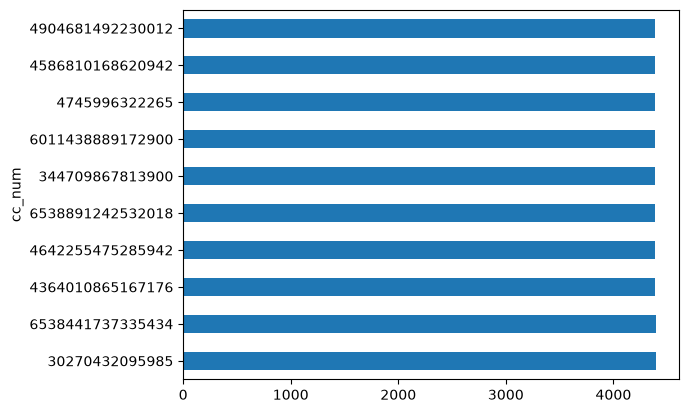

In [67]:
df["cc_num"].value_counts().head(10).plot(kind="barh")

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>999 مشتری (شماره کارت)</strong> داریم و تعداد تراکنش هر کدام بین <strong>6</strong> و <strong>4,392</strong> است.</li>
<li dir="rtl" align="right">بیشترین سهم فقط <strong>0.237٪</strong> از کل تراکنش‌هاست. پس هیچ مشتری‌ای بر داده مسلط نیست.</li>
<li dir="rtl" align="right">ده کارت اول فاصله خیلی کمی با هم دارند (حدود 4,384 تا 4,392 تراکنش).</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">11. فروشنده (<code dir="ltr">merchant</code>)</h3>
<p dir="rtl" align="right">چون حدود 700 فروشنده داریم، فقط 10 فروشنده برتر را نشان می‌دهیم: تعداد تراکنش، درصد، نمودار تعداد، و در آخر فروشنده‌هایی که <strong>مجموع مبلغ تراکنش</strong> بالاتری دارند. برای این کار <code dir="ltr">groupby("merchant")["amt"].sum()</code> مبلغ هر فروشنده را جمع می‌زند و <code dir="ltr">sort_values(ascending=False)</code> از بیشترین به کمترین مرتب می‌کند.</p>
</div>

In [68]:
df["merchant"].value_counts().head(10)

merchant
fraud_Kilback LLC        6262
fraud_Cormier LLC        5246
fraud_Schumm PLC         5195
fraud_Kuhn LLC           5031
fraud_Boyer PLC          4999
fraud_Dickinson Ltd      4953
fraud_Emard Inc          3867
fraud_Cummerata-Jones    3860
fraud_Corwin-Collins     3853
fraud_Rodriguez Group    3843
Name: count, dtype: int64

In [69]:
df["merchant"].value_counts(normalize=True).head(10) * 100

merchant
fraud_Kilback LLC        0.338049
fraud_Cormier LLC        0.283201
fraud_Schumm PLC         0.280448
fraud_Kuhn LLC           0.271594
fraud_Boyer PLC          0.269867
fraud_Dickinson Ltd      0.267384
fraud_Emard Inc          0.208757
fraud_Cummerata-Jones    0.208379
fraud_Corwin-Collins     0.208001
fraud_Rodriguez Group    0.207461
Name: proportion, dtype: float64

<Axes: ylabel='merchant'>

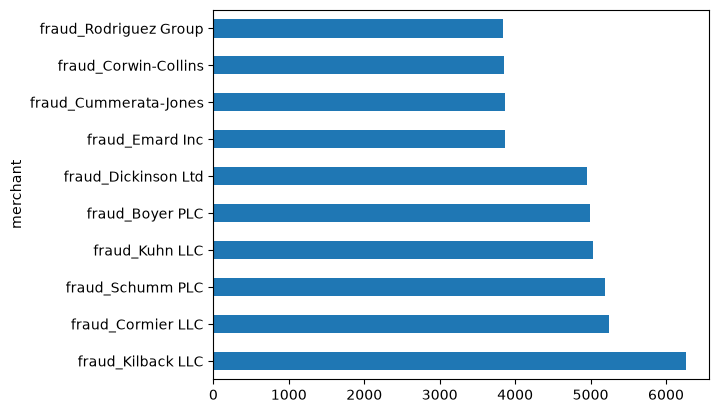

In [70]:
df["merchant"].value_counts().head(10).plot(kind="barh")

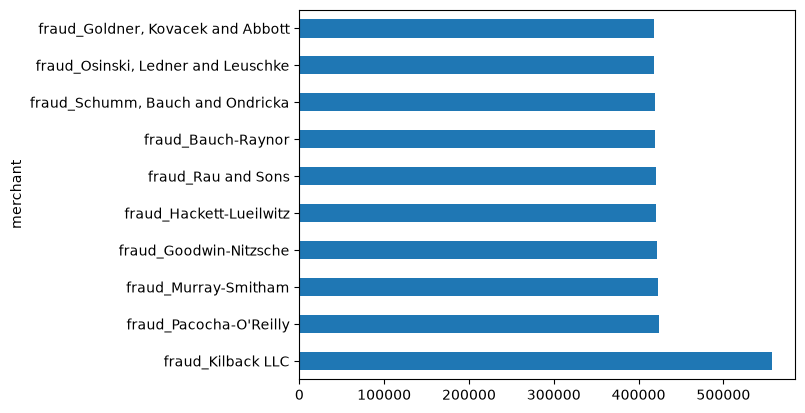

In [71]:
merchant_max = df.groupby("merchant")["amt"].sum().sort_values(ascending=False).head(10)

merchant_max.plot(kind="barh")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">از نظر تعداد، <strong>شش فروشنده اول</strong> با فاصله از بقیه‌اند (از <code dir="ltr">Kilback LLC</code> با 6,262 تراکنش تا <code dir="ltr">Dickinson Ltd</code> با 4,953). فروشنده‌های هفتم تا دهم همگی حدود 3,850 تراکنش دارند.</li>
<li dir="rtl" align="right">بیشترین سهم مال <code dir="ltr">Kilback LLC</code> و فقط حدود <strong>0.34٪</strong> است، پس فروشنده مسلطی نداریم.</li>
<li dir="rtl" align="right">از نظر مجموع مبلغ هم <code dir="ltr">Kilback LLC</code> اول است و با فاصله از بقیه قرار دارد. به یاد داشته باش که در نمودار افقی بزرگ‌ترین مقدار پایین نمودار می‌آید.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">12. دسته خرید (<code dir="ltr">category</code>)</h3>
<p dir="rtl" align="right">اول پنج دسته‌ای که بیشترین تراکنش را دارند و درصد همه دسته‌ها را می‌بینیم. دو نمودار کنار هم کشیده شده‌اند: یکی <strong>تعداد</strong> و یکی <strong>نسبت</strong> (شکلشان یکی است و فقط مقیاس محور عمودی فرق دارد).</p>
</div>

In [72]:
df["category"].value_counts().sort_values(ascending=False).head()

category
gas_transport    188029
grocery_pos      176191
home             175460
shopping_pos     166463
kids_pets        161727
Name: count, dtype: int64

In [73]:
df["category"].value_counts(normalize=True) * 100

category
gas_transport     10.150594
grocery_pos        9.511529
home               9.472067
shopping_pos       8.986371
kids_pets          8.730702
shopping_net       7.521186
entertainment      7.240252
food_dining        7.057300
personal_care      7.022534
health_fitness     6.615925
misc_pos           6.166561
misc_net           4.893883
grocery_net        3.502387
travel             3.128708
Name: proportion, dtype: float64

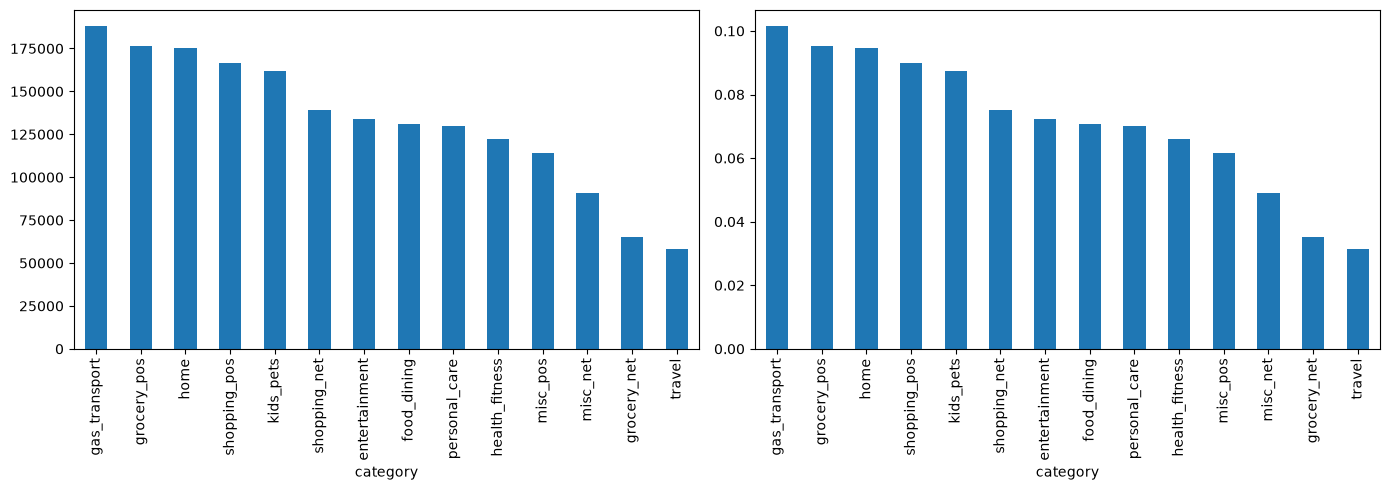

In [74]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

df["category"].value_counts().plot(kind="bar", ax=ax[0])
df["category"].value_counts(normalize=True).plot(kind="bar", ax=ax[1])

plt.tight_layout()
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">مجموع مبلغ تراکنش در هر دسته</h4>
<p dir="rtl" align="right">اینجا به‌جای تعداد، <strong>مجموع مبلغ</strong> تراکنش‌های هر دسته را حساب می‌کنیم و از بیشترین به کمترین مرتب می‌کنیم.</p>
</div>

In [75]:
category_amt = df.groupby("category")["amt"].sum().sort_values(ascending=False)
category_amt

category
grocery_pos       20550944.0
shopping_pos      13135052.0
shopping_net      12112930.0
gas_transport     11935568.0
home              10209698.0
kids_pets          9303807.0
entertainment      8602727.0
misc_net           7268762.0
misc_pos           7159471.5
food_dining        6666407.5
health_fitness     6628642.0
travel             6477809.0
personal_care      6250310.5
grocery_net        3483204.0
Name: amt, dtype: float32

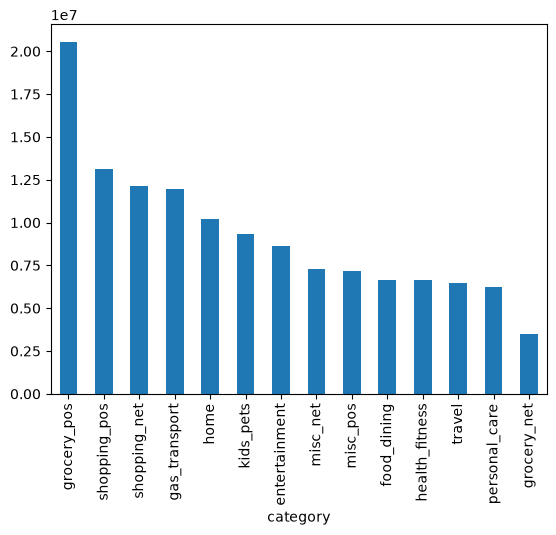

In [76]:
category_amt.plot(kind="bar")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">مقایسه تعداد و مبلغ در یک تصویر</h4>
<p dir="rtl" align="right">برای اینکه رم پر نشود، اول داده را خلاصه می‌کنیم و بعد رسم می‌کنیم (اگر ستون خام 1.85 میلیون ردیفی را به <code dir="ltr">plt.bar</code> بدهیم، برای هر ردیف یک میله ساخته می‌شود). با <code dir="ltr">.index</code> اسم دسته‌ها، با <code dir="ltr">category_count.values</code> تعداد تراکنش هر دسته و با <code dir="ltr">category_amt.values</code> مجموع مبلغ هر دسته را می‌گیریم.</p>
</div>

In [77]:
category_count = df["category"].value_counts()

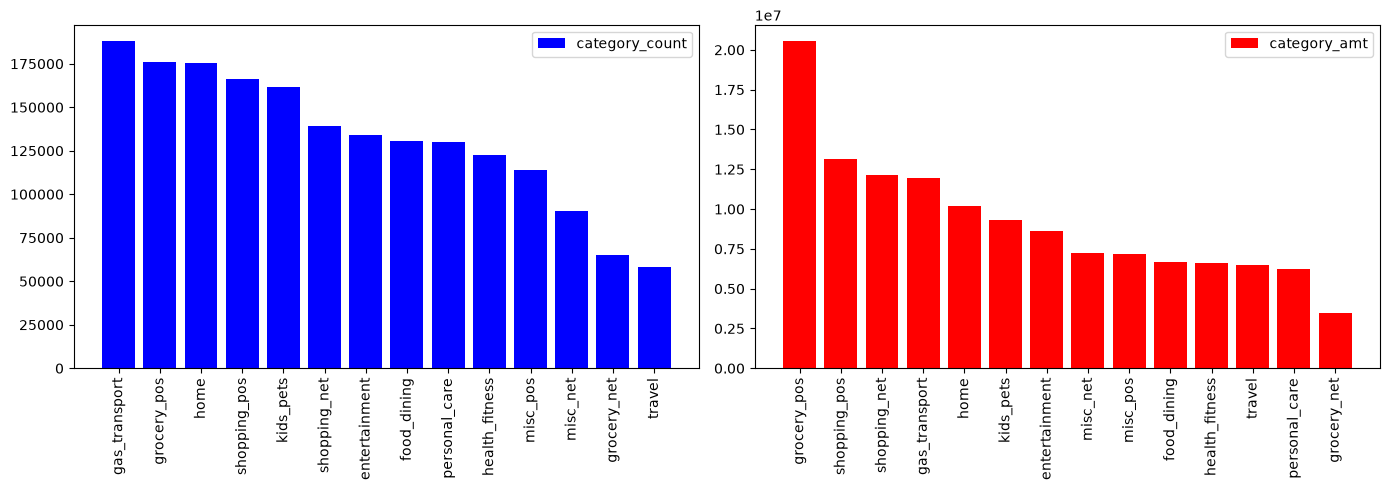

In [78]:
plt.figure(figsize=(14, 5))

plt.subplot(121)
plt.bar(category_count.index.astype(str), category_count.values, color="blue", label="category_count")
plt.xticks(rotation=90)
plt.legend()

plt.subplot(122)
plt.bar(category_amt.index.astype(str), category_amt.values, color="red", label="category_amt")
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">پنج دسته‌ای که بیشترین تراکنش را دارند به ترتیب <code dir="ltr">gas_transport</code> (188,029)، <code dir="ltr">grocery_pos</code> (176,191)، <code dir="ltr">home</code> (175,460)، <code dir="ltr">shopping_pos</code> (166,463) و <code dir="ltr">kids_pets</code> (161,727) هستند و هر کدام حدود 9 تا 10 درصد کل تراکنش‌ها را دارند. کمترین تعداد مال <code dir="ltr">travel</code> (57,956) است.</li>
<li dir="rtl" align="right">بیشترین <strong>مجموع مبلغ</strong> را <code dir="ltr">grocery_pos</code> دارد (حدود 20.55 میلیون دلار).</li>
<li dir="rtl" align="right">پس بیشترین <strong>تعداد</strong> خرید در <code dir="ltr">gas_transport</code> انجام شده، ولی مبلغ خرید در <code dir="ltr">grocery_pos</code> بیشتر است. یعنی میانگین هر خرید در <code dir="ltr">grocery_pos</code> بالاتر است (از تقسیم تقریبی: حدود 116 دلار در برابر حدود 63 دلار).</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">13. مبلغ تراکنش (<code dir="ltr">amt</code>)</h3>
<h4 dir="rtl" align="right">13.1 شکل توزیع</h4>
<p dir="rtl" align="right">اول هیستوگرام روی <strong>کل بازه</strong> و بعد هیستوگرام روی بازه <strong>0 تا 200 دلار</strong>.</p>
<p dir="rtl" align="right"><strong>چرا فقط تا 200 دلار؟</strong> بیشتر تراکنش‌ها مبلغ کمی دارند (75٪ زیر حدود 83 دلار) و بیشترین مبلغ به 28,948 دلار می‌رسد. رسم هیستوگرام روی کل بازه باعث می‌شود همه داده در یک میله جمع شود و شکل توزیع دیده نشود. بازه 0 تا 200 دلار حدوداً همان حد بالای روش IQR (حدود 193 دلار) است و بخش اصلی توزیع را نشان می‌دهد.</p>
</div>

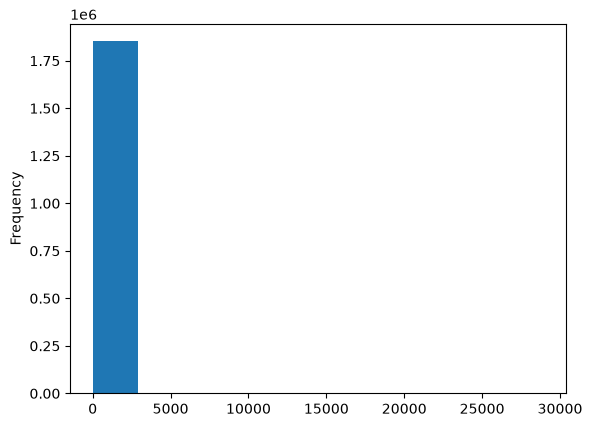

In [79]:
df["amt"].plot(kind="hist")
plt.show()

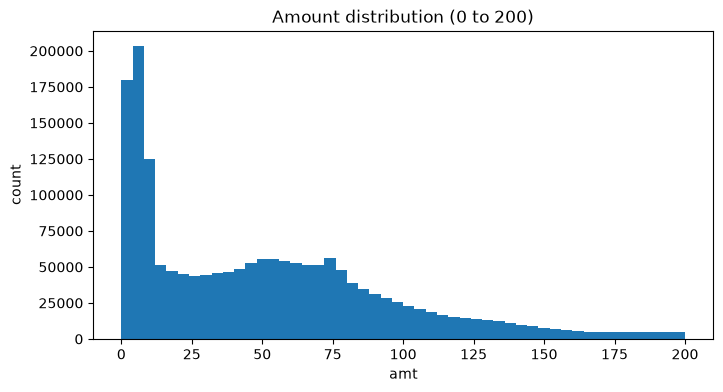

In [80]:
plt.figure(figsize=(8, 4))
plt.hist(df["amt"], bins=50, range=(0, 200))
plt.title("Amount distribution (0 to 200)")
plt.xlabel("amt")
plt.ylabel("count")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> در نمودار کل بازه همه داده سمت چپ جمع شده است. در نمودار تا 200 دلار یک قله خیلی بلند در مبلغ‌های کم (حدود 0 تا 12 دلار)، یک برآمدگی ملایم حدود 50 تا 75 دلار و بعد کاهش تدریجی دیده می‌شود. یعنی توزیع به <strong>راست چوله</strong> است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">13.2 چولگی، میانگین، میانه و پراکندگی</h4>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>چولگی، میانگین، میانه و مد</strong> را کنار هم می‌بینیم.</li>
<li dir="rtl" align="right"><strong>دامنه</strong> (<code dir="ltr">amt_range</code>) بیشترین مبلغ منهای کمترین مبلغ است.</li>
<li dir="rtl" align="right"><strong>ضریب تغییرات</strong> انحراف معیار تقسیم بر میانگین است. اگر نزدیک یا بیشتر از 1 باشد، پراکندگی نسبت به میانگین خیلی زیاد است.</li>
<li dir="rtl" align="right">درصد تراکنش‌های کمتر از 5 دلار.</li>
</ul>
</div>

In [81]:
df["amt"].skew(), df["amt"].mean(), df["amt"].median(), df["amt"].mode()[0]

(np.float32(40.81281),
 np.float32(70.06357),
 np.float32(47.45),
 np.float32(1.14))

In [82]:
amt_range = df["amt"].max() - df["amt"].min()
amt_range

np.float32(28947.9)

In [83]:
df["amt"].std() / df["amt"].mean()

np.float32(2.2729926)

In [84]:
(df["amt"] < 5).mean() * 100

np.float64(12.535778025625218)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>چولگی 40.81</strong> است، عدد خیلی بزرگ و مثبت، یعنی چولگی شدید به راست. میانگین هم فاصله زیادی از میانه دارد.</li>
<li dir="rtl" align="right">در چنین توزیعی ترتیب این است: <strong>میانگین (70.06) &gt; میانه (47.45) &gt; مد (1.14)</strong>. میانگین به‌خاطر مبلغ‌های بزرگ بالا کشیده شده و نماینده یک تراکنش معمولی نیست.</li>
<li dir="rtl" align="right"><strong>دامنه</strong> حدود 28,947.9 دلار و <strong>ضریب تغییرات</strong> حدود 2.3 است. پس پراکندگی نسبت به میانگین خیلی زیاد است.</li>
<li dir="rtl" align="right">حدود <strong>12.5٪</strong> تراکنش‌ها خیلی کم‌مبلغ (زیر 5 دلار) هستند.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">13.3 داده‌های پرت</h4>
<p dir="rtl" align="right">داده پرت را با دو روش پیدا می‌کنیم و نتیجه را مقایسه می‌کنیم:</p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>روش سه سیگما:</strong> هر مقداری که از «میانگین + 3 برابر انحراف معیار» بیشتر (یا از «میانگین − 3 برابر انحراف معیار» کمتر) باشد پرت است (<code dir="ltr">outlier_1</code>). حد بالا حدود 547.8 دلار است.</li>
<li dir="rtl" align="right"><strong>روش IQR:</strong> با <code dir="ltr">IQR = Q3 - Q1</code>، هر مقدار بالاتر از <code dir="ltr">Q3 + 1.5 × IQR</code> پرت است (<code dir="ltr">outlier_2</code>). حد بالا حدود 193.3 دلار است. حد پایین هر دو روش منفی می‌شود و چون کمترین مبلغ 1 دلار است، پرت پایینی نداریم.</li>
</ul>
<p dir="rtl" align="right">در آخر <code dir="ltr">outlier_1["cc_num"].unique()</code> کارت‌هایی را نشان می‌دهد که تراکنش پرت دارند و تعداد و درصد پرت‌های هر دو روش را می‌شماریم.</p>
</div>

In [85]:
amt_mean = df["amt"].mean()
amt_std = df["amt"].std()

upper_bound_1 = amt_mean + amt_std * 3
lower_bound_1 = amt_mean - amt_std * 3

outlier_1 = df[(df["amt"] > upper_bound_1) | (df["amt"] < lower_bound_1)]
outlier_1["cc_num"].unique()

[4060579726528237, 4311368326621416041, 571844099986, 4509142395811241, 4265776278887457, ..., 4295296907373, 4087542780207162, 3588001568691267, 2714019737356678, 2242176657877538]
Length: 997
Categories (999, int64): [60416207185, 60422928733, 60423098130, 60427851591, ..., 4973530368125489546, 4980323467523543940, 4989847570577635369, 4992346398065154184]

In [86]:
amt_min, amt_q1, amt_q2, amt_q3, amt_max = df["amt"].describe()[["min", "25%", "50%", "75%", "max"]]
amt_iqr = amt_q3 - amt_q1
upper_bound_2 = amt_q3 + amt_iqr * 1.5

outlier_2 = df[df["amt"] > upper_bound_2]

In [87]:
outlier_1_len = len(outlier_1)
outlier_2_len = len(outlier_2)
outlier_1_len, outlier_2_len

(17846, 95054)

In [88]:
outlier_1_range = len(outlier_1) / len(df) * 100
outlier_2_range = len(outlier_2) / len(df) * 100

outlier_1_range, outlier_2_range

(0.963401954443817, 5.131413727317191)

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>چرا IQR؟</strong> توزیع مبلغ به‌شدت به راست چوله است و میانگین از میانه خیلی بزرگ‌تر است. روش سه سیگما به میانگین و انحراف معیار تکیه دارد که خودشان تحت تأثیر مبلغ‌های بزرگ‌اند و فرض می‌کند توزیع تقریباً <strong>نرمال و متقارن</strong> است، پس برای این داده مناسب نیست. روش IQR فقط به چارک‌ها وابسته است و به مقدارهای خیلی بزرگ حساس نیست، برای همین آن را انتخاب کردیم.</p>
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">روش سه سیگما <strong>17,846</strong> تراکنش (حدود <strong>0.96٪</strong>) را پرت می‌داند و روش IQR <strong>95,054</strong> تراکنش (حدود <strong>5.13٪</strong>).</li>
<li dir="rtl" align="right">IQR هم چون برای توزیع متقارن طراحی شده، در داده چوله تعداد زیادی تراکنش را پرت اعلام می‌کند. این‌ها لزوماً خطا نیستند و فقط تراکنش‌های بزرگ‌تر از حد معمول‌اند. با این حال از روش سه سیگما مناسب‌تر است.</li>
<li dir="rtl" align="right"><strong>997 کارت از 999 کارت</strong> حداقل یک تراکنش پرت (روش اول) دارند، یعنی تراکنش‌های پرمبلغ بین تقریباً همه مشتری‌ها پخش شده است.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">13.4 باکس‌پلات</h4>
<p dir="rtl" align="right">باکس‌پلات اول با نقطه‌های پرت و دومی بدون نقطه‌های پرت (<code dir="ltr">showfliers=False</code>) و افقی رسم شده است.</p>
</div>

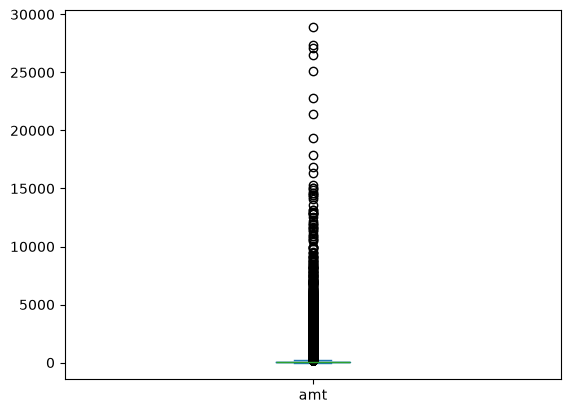

In [89]:
df["amt"].plot(kind="box")
plt.show()

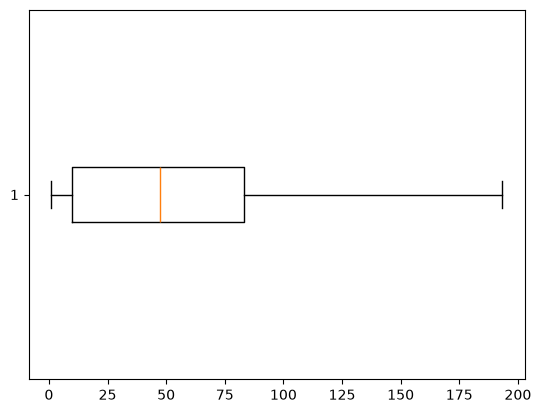

In [90]:
plt.boxplot(df["amt"], showfliers=False, orientation="horizontal")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> در نمودار دوم جعبه (50٪ میانی داده) تقریباً از 9.6 تا 83 دلار است و میانه حدود 47 دلار. سبیل بالایی خیلی بلندتر از سبیل پایینی است. یعنی <strong>تعداد تراکنش‌های کم‌مبلغ زیاد و تعداد تراکنش‌های پرمبلغ کم است.</strong></p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">14. جنسیت (<code dir="ltr">gender</code>)</h3>
<p dir="rtl" align="right">تعداد و درصد تراکنش زنان و مردان و نمودار میله‌ای.</p>
</div>

In [91]:
df["gender"].value_counts()

gender
F    1014749
M     837645
Name: count, dtype: int64

In [92]:
(df["gender"].value_counts() / df["gender"].count()) * 100

gender
F    54.780408
M    45.219592
Name: count, dtype: float64

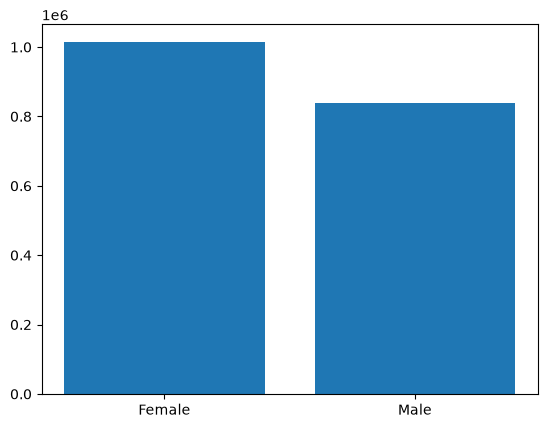

In [93]:
counts = df["gender"].value_counts()
counts.index = counts.index.map({"F": "Female", "M": "Male"})

plt.bar(counts.index, counts.values)
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> زنان <strong>1,014,749</strong> تراکنش (<strong>54.78٪</strong>) و مردان <strong>837,645</strong> تراکنش (<strong>45.22٪</strong>) دارند. سهم زنان کمی بیشتر است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">15. جمعیت شهر (<code dir="ltr">city_pop</code>)</h3>
<h4 dir="rtl" align="right">15.1 توزیع</h4>
<p dir="rtl" align="right">آمار توصیفی، هیستوگرام و بعد چولگی، میانگین، میانه و مد. هر ردیف یک <strong>تراکنش</strong> است، پس این آمار درباره «جمعیت شهر هر تراکنش» است نه خود شهرها.</p>
</div>

In [94]:
df["city_pop"].describe()

count    1.852394e+06
mean     8.864367e+04
std      3.014876e+05
min      2.300000e+01
25%      7.410000e+02
50%      2.443000e+03
75%      2.032800e+04
max      2.906700e+06
Name: city_pop, dtype: float64

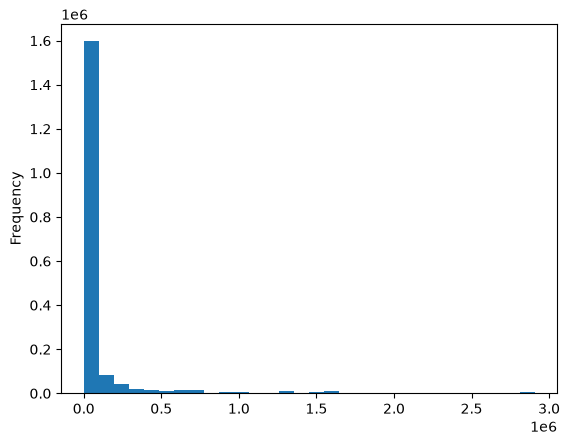

In [95]:
df["city_pop"].plot(kind="hist", bins=30)
plt.show()

In [96]:
df["city_pop"].skew(), df["city_pop"].mean(), df["city_pop"].median(), df["city_pop"].mode()[0]

(np.float64(5.590804561529254),
 np.float64(88643.67450931066),
 np.float64(2443.0),
 np.int32(606))

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> چولگی <strong>5.59</strong> است، یعنی چولگی زیادی به سمت راست داریم. به همین دلیل میانگین (88,644) از میانه (2,443) و آن از مد (606) بیشتر است. در حالت متقارن این سه تقریباً برابرند. یعنی نیمی از تراکنش‌ها در شهرهایی با جمعیت کمتر از حدود 2,443 نفر انجام شده است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">15.2 داده‌های پرت</h4>
<p dir="rtl" align="right">با روش IQR (مثل <code dir="ltr">amt</code>) تراکنش‌های پرت را می‌شماریم و باکس‌پلات را یک بار با پرت‌ها و یک بار بدون آن‌ها می‌کشیم.</p>
</div>

In [97]:
city_pop_q1 = df["city_pop"].quantile(0.25)
city_pop_q2 = df["city_pop"].quantile(0.50)
city_pop_q3 = df["city_pop"].quantile(0.75)
city_pop_iqr = city_pop_q3 - city_pop_q1

city_pop_upper_bound = city_pop_q3 + city_pop_iqr * 1.5
city_pop_lower_bound = city_pop_q1 - city_pop_iqr * 1.5

city_pop_outlier = (df["city_pop"] > city_pop_upper_bound) | (df["city_pop"] < city_pop_lower_bound)
city_pop_outlier.sum()

np.int64(346191)

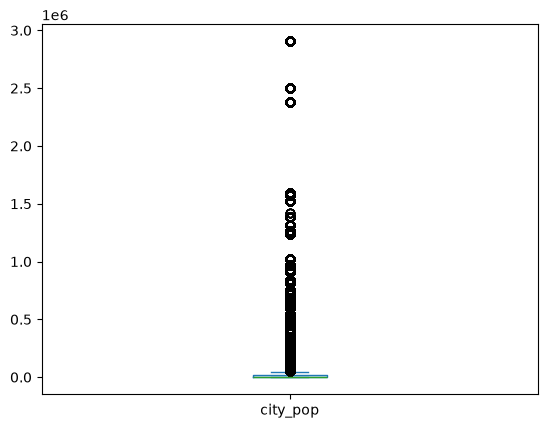

In [98]:
df["city_pop"].plot(kind="box")
plt.show()

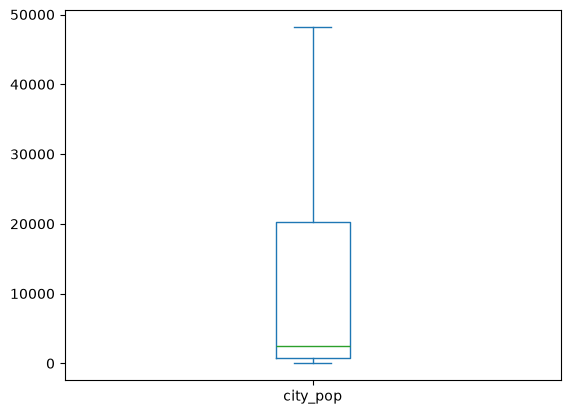

In [161]:
df["city_pop"].plot(kind="box", showfliers=False)
plt.show()

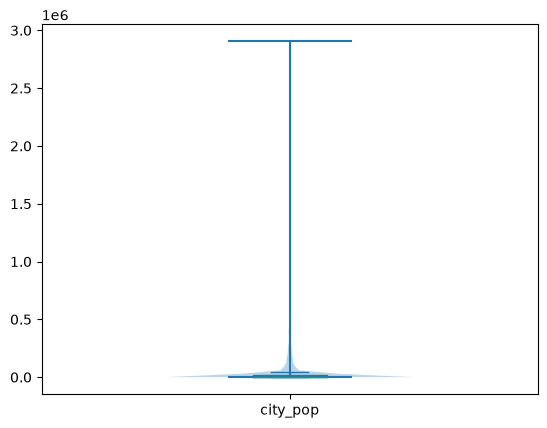

In [163]:
df["city_pop"].plot(kind="box", showfliers=False)
plt.violinplot(df["city_pop"])
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> حد بالا حدود 49,708 نفر است (حد پایین منفی است) و <strong>346,191</strong> تراکنش، حدود <strong>18.69٪</strong>، بالاتر از آن است. این‌ها تراکنش‌های شهرهای بزرگ‌اند، نه داده خراب. باکس‌پلات بدون پرت‌ها نشان می‌دهد بیشتر داده در جمعیت‌های کم متمرکز است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h4 dir="rtl" align="right">15.3 تراکنش‌های بین چارک اول و چارک دوم</h4>
<p dir="rtl" align="right">تعداد تراکنش‌هایی که جمعیت شهرشان بین چارک اول (741) و چارک دوم یا میانه (2,443) است.</p>
</div>

In [100]:
len(df[(df["city_pop"] > city_pop_q1) & (df["city_pop"] < city_pop_q2)])

462438

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> <strong>462,438</strong> تراکنش (حدود <strong>25٪</strong>) در این بازه‌اند. این عدد طبق تعریف چارک‌ها همیشه حدود یک‌چهارم کل است، پس نشان نمی‌دهد «بیشتر» تراکنش‌ها اینجا هستند. چیزی که می‌فهمیم این است که یک‌چهارم تراکنش‌ها در بازه باریک 741 تا 2,443 نفر جمع شده‌اند.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">16. سن مشتری (<code dir="ltr">age</code>)</h3>
<p dir="rtl" align="right">سن مشتری در لحظه تراکنش: آمار توصیفی، چولگی و معیارهای مرکزی، هیستوگرام، پرت‌ها با روش IQR و باکس‌پلات همراه با نمودار ویولن (<code dir="ltr">violinplot</code>) که شکل توزیع را نشان می‌دهد.</p>
</div>

In [101]:
df["age"].describe()

count    1.852394e+06
mean     4.576393e+01
std      1.741238e+01
min      1.300000e+01
25%      3.200000e+01
50%      4.400000e+01
75%      5.700000e+01
max      9.600000e+01
Name: age, dtype: float64

In [102]:
df["age"].skew(), df["age"].mean(), df["age"].median(), df["age"].mode()[0]

(np.float64(0.6097999424029731),
 np.float64(45.76393305096),
 np.float64(44.0),
 np.int8(47))

<Axes: ylabel='Frequency'>

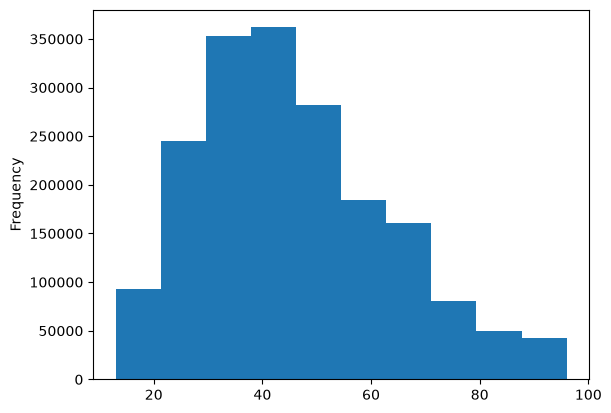

In [103]:
df["age"].plot(kind="hist")

In [104]:
age_q1 = df["age"].quantile(0.25)
age_q2 = df["age"].quantile(0.50)
age_q3 = df["age"].quantile(0.75)
age_iqr = age_q3 - age_q1

age_upper_bound = age_q3 + age_iqr * 1.5
age_lower_bound = age_q1 - age_iqr * 1.5

age_outlier = df[(df["age"] > age_upper_bound) | (df["age"] < age_lower_bound)]
len(age_outlier)

435

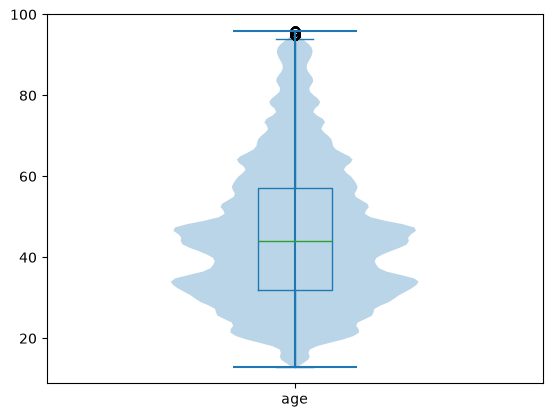

In [105]:
df["age"].plot(kind="box")
plt.violinplot(df["age"])
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">سن‌ها از <strong>13</strong> تا <strong>96</strong> سال هستند. میانگین حدود 45.8 و میانه 44 است.</li>
<li dir="rtl" align="right"><strong>چولگی 0.61</strong> است. چولگی به راست داریم ولی ملایم است (خیلی کمتر از <code dir="ltr">amt</code>) و توزیع نسبتاً متقارن است.</li>
<li dir="rtl" align="right">هیستوگرام و ویولن پهن‌ترین بخش را حدود 30 تا 50 سال نشان می‌دهند و دم سمت سن‌های بالا بلندتر است.</li>
<li dir="rtl" align="right">حد بالای IQR حدود 94.5 است و فقط <strong>435</strong> تراکنش (سن 95 و 96، حدود 0.02٪) پرت‌اند. تعداد پرت‌ها کم است و باعث چولگی ملایم شده‌اند.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">17. گروه سنی (<code dir="ltr">age group</code>)</h3>
<p dir="rtl" align="right">تعداد و درصد تراکنش در هر گروه سنی و نمودار میله‌ای.</p>
</div>

In [106]:
df["age group"].value_counts()

age group
26-35    422715
36-45    383822
46-55    352001
66+      261459
56-65    233259
<=25     199138
Name: count, dtype: int64

In [107]:
df["age group"].value_counts(normalize=True) * 100

age group
26-35    22.819929
36-45    20.720322
46-55    19.002491
66+      14.114654
56-65    12.592299
<=25     10.750305
Name: proportion, dtype: float64

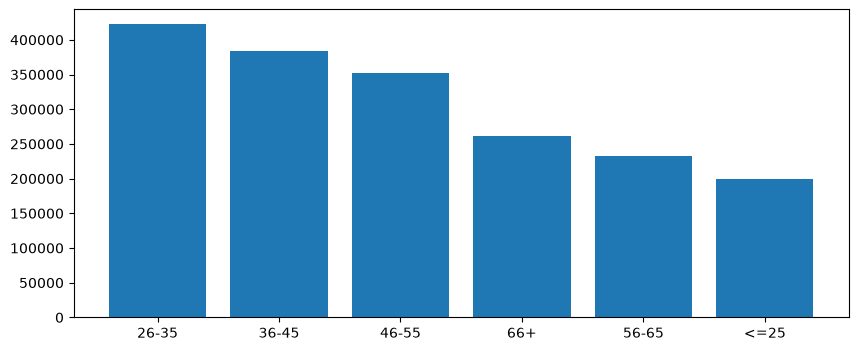

In [108]:
age_group_column = df["age group"].value_counts()
age_group_index = df["age group"].value_counts().index

plt.figure(figsize=(10, 4))
plt.bar(age_group_index, age_group_column)
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> گروه <strong>26-35</strong> سال بیشترین تراکنش را دارد (422,715، <strong>22.82٪</strong>)، بعد <strong>36-45</strong> (20.72٪) و <strong>46-55</strong> (19.00٪). گروه‌های <code dir="ltr">66+</code> (14.11٪)، <code dir="ltr">56-65</code> (12.59٪) و <code dir="ltr">&lt;=25</code> (10.75٪) بعدی‌اند. بازه‌ها هم‌اندازه نیستند، پس برای مقایسه ریسک گروه‌ها در بخش بعد از نرخ تقلب استفاده می‌کنیم.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">18. ایالت (<code dir="ltr">state</code>)</h3>
<p dir="rtl" align="right">تعداد و درصد تراکنش در هر ایالت و نمودار میله‌ای.</p>
</div>

In [109]:
df["state"].value_counts()

state
TX    135269
NY    119419
PA    114173
CA     80495
OH     66627
MI     65825
IL     62212
FL     60775
AL     58521
MO     54904
MN     45433
AR     44611
NC     43134
VA     41756
WI     41738
SC     41731
KY     40981
IN     39539
IA     38804
OK     38050
MD     37345
GA     37340
WV     36529
NJ     35131
NE     34425
KS     32939
MS     30021
LA     29953
WY     27776
WA     27040
OR     26408
TN     24913
ME     23433
NM     23427
ND     21183
CO     19766
SD     17574
MA     17562
VT     16812
MT     16806
AZ     15362
UT     15357
NH     11727
CT     10979
NV      8058
ID      8035
DC      5130
HI      3649
AK      2963
RI       745
DE         9
Name: count, dtype: int64

In [110]:
df["state"].value_counts(normalize=True) * 100

state
TX    7.302388
NY    6.446739
PA    6.163538
CA    4.345458
OH    3.596805
MI    3.553510
IL    3.358465
FL    3.280889
AL    3.159209
MO    2.963948
MN    2.452664
AR    2.408289
NC    2.328554
VA    2.254164
WI    2.253192
SC    2.252814
KY    2.212326
IN    2.134481
IA    2.094803
OK    2.054099
MD    2.016040
GA    2.015770
WV    1.971989
NJ    1.896519
NE    1.858406
KS    1.778185
MS    1.620660
LA    1.616989
WY    1.499465
WA    1.459733
OR    1.425615
TN    1.344908
ME    1.265012
NM    1.264688
ND    1.143547
CO    1.067052
SD    0.948718
MA    0.948070
VT    0.907582
MT    0.907258
AZ    0.829305
UT    0.829035
NH    0.633073
CT    0.592692
NV    0.435005
ID    0.433763
DC    0.276939
HI    0.196988
AK    0.159955
RI    0.040218
DE    0.000486
Name: proportion, dtype: float64

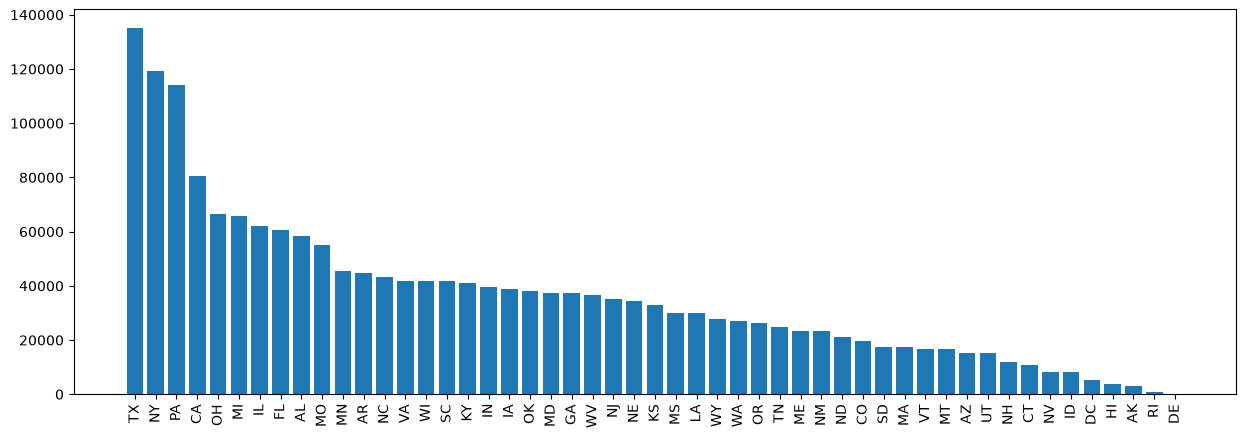

In [164]:
state_column = df["state"].value_counts()
state_index = df["state"].value_counts().index

plt.figure(figsize=(15, 5))
plt.bar(state_index, state_column)
plt.xticks(rotation=90)
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> <strong>51 مقدار</strong> داریم (50 ایالت و <code dir="ltr">DC</code>). بیشترین تراکنش مال <code dir="ltr">TX</code> (135,269، 7.30٪)، <code dir="ltr">NY</code> (119,419) و <code dir="ltr">PA</code> (114,173) است که روی هم حدود 19.9٪ کل را دارند. کمترین‌ها <code dir="ltr">DE</code> با 9 تراکنش و <code dir="ltr">RI</code> با 745 تراکنش‌اند.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">19. شهر (<code dir="ltr">city</code>)</h3>
<p dir="rtl" align="right"><strong>906 شهر</strong> داریم، پس 10 شهر پرتراکنش را نشان می‌دهیم.</p>
</div>

In [112]:
df["city"].value_counts().head(10)

city
Birmingham     8040
San Antonio    7312
Utica          7309
Phoenix        7297
Meridian       7289
Warren         6584
Conway         6574
Cleveland      6572
Thomas         6571
Houston        5865
Name: count, dtype: int64

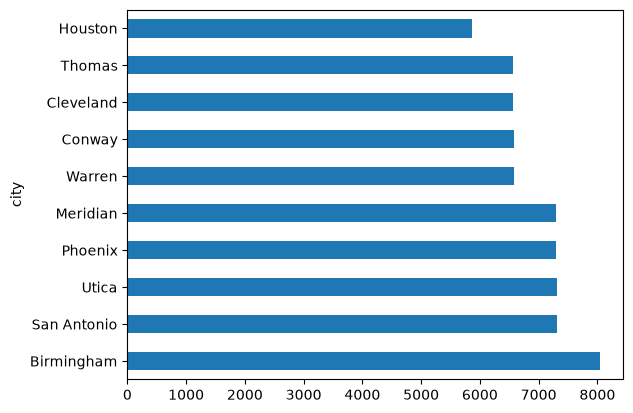

In [166]:
df["city"].value_counts().head(10).plot(kind="barh")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> <code dir="ltr">Birmingham</code> با <strong>8,040</strong> تراکنش اول است و دهمین شهر (<code dir="ltr">Houston</code>) 5,865 تراکنش دارد. بیشترین سهم فقط حدود 0.43٪ است، پس شهر مسلطی نداریم.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">20. شغل (<code dir="ltr">job</code>)</h3>
<p dir="rtl" align="right"><strong>497 شغل</strong> داریم، پس 10 شغل پرتراکنش را نشان می‌دهیم.</p>
</div>

In [114]:
df["job"].value_counts().head(10)

job
Film/video editor             13898
Exhibition designer           13167
Surveyor, land/geomatics      12436
Naval architect               12434
Materials engineer            11711
Designer, ceramics/pottery    11688
Environmental consultant      10974
Financial adviser             10963
Systems developer             10962
IT trainer                    10943
Name: count, dtype: int64

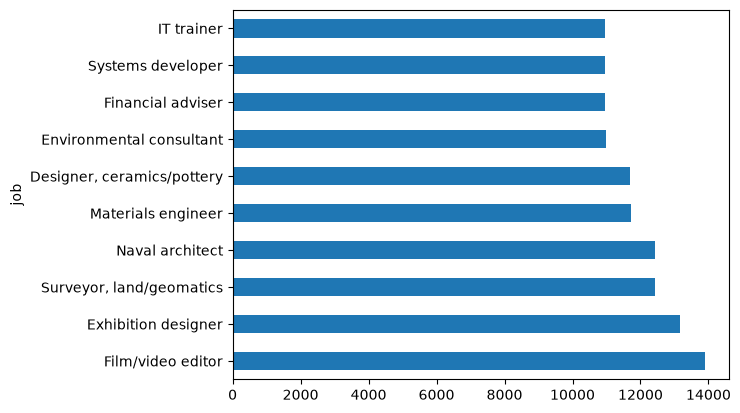

In [167]:
df["job"].value_counts().head(10).plot(kind="barh")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> <code dir="ltr">Film/video editor</code> با <strong>13,898</strong> تراکنش اول است و ده شغل اول بین 10,943 تا 13,898 تراکنش دارند. بیشترین سهم حدود 0.75٪ است، پس شغل مسلطی نداریم.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">21. روز هفته (<code dir="ltr">weekday</code>)</h3>
<p dir="rtl" align="right">تعداد و درصد تراکنش در هر روز هفته و نمودار میله‌ای (ترتیب نمودار بر اساس تعداد است).</p>
</div>

In [116]:
df["weekday"].value_counts()

weekday
Monday       369418
Sunday       343677
Tuesday      270340
Saturday     263227
Friday       215078
Thursday     206741
Wednesday    183913
Name: count, dtype: int64

In [117]:
df["weekday"].value_counts(normalize=True) * 100

weekday
Monday       19.942734
Sunday       18.553126
Tuesday      14.594087
Saturday     14.210098
Friday       11.610813
Thursday     11.160747
Wednesday     9.928395
Name: proportion, dtype: float64

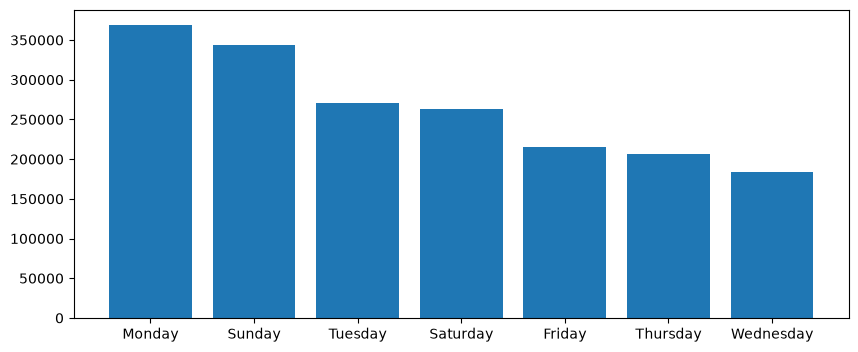

In [118]:
weekday_column = df["weekday"].value_counts()
weekday_index = df["weekday"].value_counts().index

plt.figure(figsize=(10, 4))
plt.bar(weekday_index, weekday_column)
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> دوشنبه (<strong>19.94٪</strong>) و یکشنبه (<strong>18.55٪</strong>) بیشترین تراکنش را دارند و روی هم حدود 38.5٪ کل را شامل می‌شوند. کمترین مال چهارشنبه (9.93٪) است. پس تراکنش‌ها در هفته یکنواخت نیستند.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">22. ساعت تراکنش (<code dir="ltr">hour</code>)</h3>
<p dir="rtl" align="right">تعداد تراکنش در هر ساعت شبانه‌روز (0 تا 23) به ترتیب ساعت و به‌صورت نمودار خطی.</p>
</div>

In [119]:
df["hour"].value_counts().sort_index() 

hour
0     60655
1     61330
2     60796
3     60968
4     59938
5     60088
6     60406
7     60301
8     60498
9     60231
10    60320
11    60170
12    93294
13    93492
14    93089
15    93439
16    94289
17    93514
18    94052
19    93433
20    93081
21    93738
22    95370
23    95902
Name: count, dtype: int64

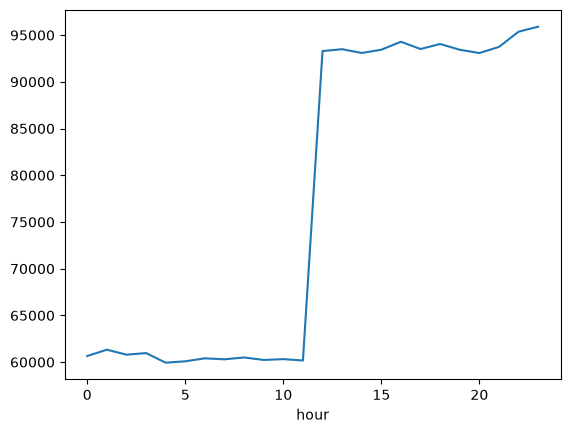

In [120]:
df["hour"].value_counts().sort_index().plot(kind="line")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> در ساعت‌های <strong>0 تا 11</strong> تعداد تراکنش تقریباً ثابت و کم است (حدود 60 هزار در هر ساعت). از ساعت <strong>12</strong> ناگهان به حدود <strong>94 هزار</strong> می‌رسد و تا ساعت 23 تقریباً ثابت می‌ماند. یعنی الگو به‌صورت یک <strong>پله</strong> است، نه افزایش تدریجی، و احتمالاً به نحوه شبیه‌سازی داده مربوط است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">23. ستون هدف (<code dir="ltr">is_fraud</code>)</h3>
<p dir="rtl" align="right">تعداد و درصد تراکنش‌های عادی و تقلبی و نمودار میله‌ای.</p>
</div>

In [121]:
df["is_fraud"].value_counts()

is_fraud
0    1842743
1       9651
Name: count, dtype: int64

In [122]:
df["is_fraud"].value_counts(normalize=True) * 100

is_fraud
0    99.478999
1     0.521001
Name: proportion, dtype: float64

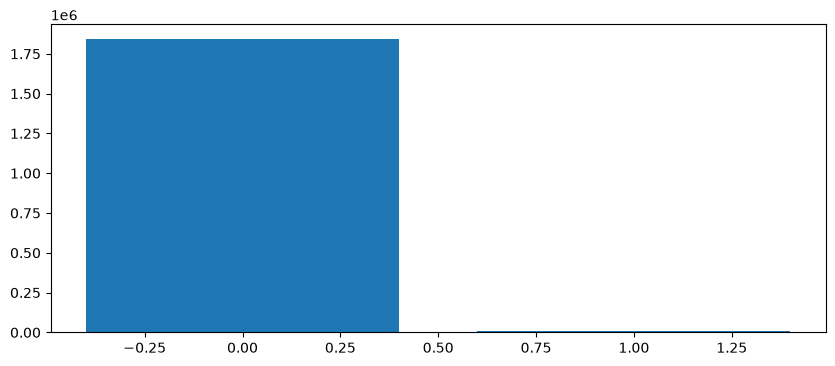

In [123]:
is_fraud_column = df["is_fraud"].value_counts()
is_fraud_index = df["is_fraud"].value_counts().index

plt.figure(figsize=(10, 4))
plt.bar(is_fraud_index, is_fraud_column)
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> <strong>1,842,743</strong> تراکنش عادی (<strong>99.479٪</strong>) و فقط <strong>9,651</strong> تراکنش تقلبی (<strong>0.521٪</strong>) داریم. داده‌های تقلبی خیلی کم‌اند و در نمودار دیده نمی‌شوند. این همان <strong>نامتوازن بودن</strong> داده است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">24. جمع‌بندی بخش دوم</h3>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>زمان:</strong> دو سال کامل (2019 و 2020).</li>
<li dir="rtl" align="right"><strong>مشتری و فروشنده:</strong> 999 کارت و 693 فروشنده؛ هیچ‌کدام بر داده مسلط نیستند.</li>
<li dir="rtl" align="right"><strong>دسته خرید:</strong> <code dir="ltr">gas_transport</code> بیشترین تعداد و <code dir="ltr">grocery_pos</code> بیشترین مجموع مبلغ را دارد.</li>
<li dir="rtl" align="right"><strong>مبلغ:</strong> چولگی شدید به راست (میانگین 70.06 &gt; میانه 47.45 &gt; مد 1.14) و روش IQR برای پرت‌ها مناسب‌تر است.</li>
<li dir="rtl" align="right"><strong>جنسیت:</strong> 54.78٪ زن و 45.22٪ مرد. <strong>سن:</strong> تقریباً متقارن با چولگی ملایم؛ بیشترین تراکنش در گروه 26-35.</li>
<li dir="rtl" align="right"><strong>جمعیت شهر:</strong> چولگی شدید و نیمی از تراکنش‌ها در شهرهای زیر 2,443 نفر.</li>
<li dir="rtl" align="right"><strong>روز هفته و ساعت:</strong> تراکنش‌ها در دوشنبه و یکشنبه بیشترند و در ساعت 12 یک پله دارند.</li>
<li dir="rtl" align="right"><strong>تقلب:</strong> فقط 0.521٪ تراکنش‌ها تقلبی است (داده نامتوازن).</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h2 dir="rtl" align="right">بخش سوم: تحلیل دومتغیره (Bivariate Analysis)</h2>
<p dir="rtl" align="right">در این بخش رابطه هر ستون را با تقلب (<code dir="ltr">is_fraud</code>) بررسی می‌کنیم. اول یک نگاه به ستون‌های نهایی داده، شامل ستون‌های جدیدی که ساختیم (<code dir="ltr">hour</code>، <code dir="ltr">weekday</code>، <code dir="ltr">month</code>، <code dir="ltr">age</code>، <code dir="ltr">age group</code>).</p>
<h3 dir="rtl" align="right">25. روش کار</h3>
<p dir="rtl" align="right">چون تراکنش‌های تقلبی خیلی کم‌اند (0.52٪) و بین تراکنش‌های عادی گم می‌شوند، به‌جای <strong>تعداد</strong> از <strong>نرخ تقلب</strong> استفاده می‌کنیم، یعنی در هر گروه چند درصد تراکنش‌ها تقلبی است.</p>
<p dir="rtl" align="right">برای محاسبه آن، <code dir="ltr">groupby</code> را روی ستون مورد نظر می‌زنیم و از <code dir="ltr">is_fraud</code> میانگین می‌گیریم. چون این ستون فقط 0 و 1 دارد، میانگینش در هر گروه (جمع تقلب‌ها تقسیم بر تعداد کل گروه) دقیقاً نسبت تراکنش‌های تقلبی است و ضرب در 100 آن را درصد می‌کند.</p>
</div>

In [124]:
df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,gender,city,state,zip,lat,...,job,dob,merch_lat,merch_long,is_fraud,hour,weekday,month,age,age group
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.970000,F,Moravian Falls,NC,28654,36.078800,...,"Psychologist, counselling",1988-03-09,36.011292,-82.048317,0,0,Tuesday,1,30,26-35
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.230003,F,Orient,WA,99160,48.887798,...,Special educational needs teacher,1978-06-21,49.159046,-118.186462,0,0,Tuesday,1,40,36-45
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.110001,M,Malad City,ID,83252,42.180801,...,Nature conservation officer,1962-01-19,43.150703,-112.154480,0,0,Tuesday,1,56,56-65
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.000000,M,Boulder,MT,59632,46.230598,...,Patent attorney,1967-01-12,47.034332,-112.561073,0,0,Tuesday,1,51,46-55
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.959999,M,Doe Hill,VA,24433,38.420700,...,Dance movement psychotherapist,1986-03-28,38.674999,-78.632462,0,0,Tuesday,1,32,26-35


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">26. نرخ تقلب در هر دسته خرید (<code dir="ltr">category</code>)</h3>
</div>

In [125]:
category_fraud = df.groupby("category")["is_fraud"].mean() * 100
category_fraud

category
entertainment     0.217719
food_dining       0.156813
gas_transport     0.410575
grocery_net       0.269737
grocery_pos       1.264537
health_fitness    0.150955
home              0.151032
kids_pets         0.187971
misc_net          1.303859
misc_pos          0.281890
personal_care     0.222931
shopping_net      1.592713
shopping_pos      0.634375
travel            0.269170
Name: is_fraud, dtype: float64

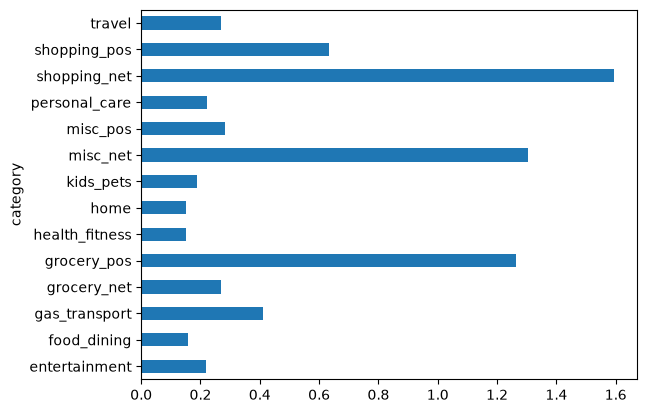

In [126]:
category_fraud.plot(kind="barh")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> بیشترین نرخ تقلب مال <code dir="ltr">shopping_net</code> (<strong>1.59٪</strong>) است. بعد از آن <code dir="ltr">misc_net</code> (1.30٪) و <code dir="ltr">grocery_pos</code> (1.26٪) قرار دارند و بعد <code dir="ltr">shopping_pos</code> (0.63٪). بقیه دسته‌ها زیر 0.5٪ هستند و کمترین نرخ مال <code dir="ltr">health_fitness</code> و <code dir="ltr">home</code> (حدود 0.15٪) است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">27. نرخ تقلب در هر ساعت (<code dir="ltr">hour</code>)</h3>
<p dir="rtl" align="right">بر اساس ساعت تراکنش، نرخ تقلب را در هر ساعت حساب می‌کنیم.</p>
</div>

In [127]:
hour_fraud = df.groupby("hour")["is_fraud"].mean() * 100
hour_fraud

hour
0     1.356854
1     1.348443
2     1.304362
3     1.317084
4     0.101772
5     0.133138
6     0.089395
7     0.119401
8     0.097524
9     0.101277
10    0.086207
11    0.098056
12    0.090038
13    0.100543
14    0.107424
15    0.107022
16    0.102875
17    0.100520
18    0.118020
19    0.112380
20    0.105285
21    0.107747
22    2.601447
23    2.546349
Name: is_fraud, dtype: float64

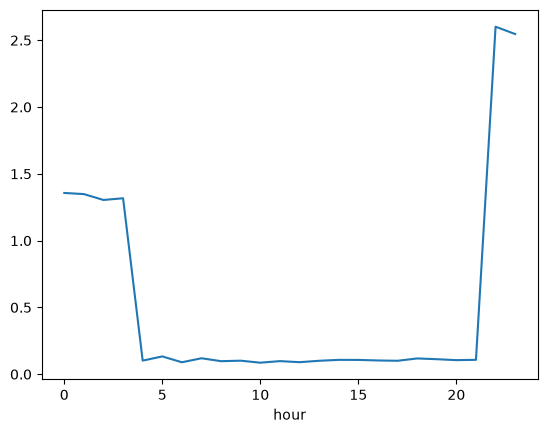

In [128]:
hour_fraud.plot(kind="line")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">از ساعت <strong>0 تا 3</strong> نرخ تقلب نسبتاً بالاست (حدود 1.3٪).</li>
<li dir="rtl" align="right">از ساعت <strong>4 تا 21</strong> نرخ کم و تقریباً ثابت است (حدود 0.1٪).</li>
<li dir="rtl" align="right">از ساعت <strong>22</strong> نرخ ناگهان بالا می‌رود و در ساعت‌های <strong>22 و 23</strong> به بیشترین مقدار خود (حدود 2.6٪) می‌رسد.</li>
<li dir="rtl" align="right">یعنی تقلب در بازه <strong>22 تا 4 صبح</strong> متمرکز است و نرخش حدود 13 تا 26 برابر روز است.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">28. نرخ تقلب در هر روز هفته (<code dir="ltr">weekday</code>)</h3>
<p dir="rtl" align="right">نرخ تقلب هر روز هفته را با روزهای دیگر مقایسه می‌کنیم (ترتیب روزها از شنبه تنظیم شده است).</p>
</div>

In [129]:
order = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekday_fraud = (df.groupby("weekday")["is_fraud"].mean() * 100).reindex(order)
weekday_fraud

weekday
Saturday     0.567191
Sunday       0.462644
Monday       0.401713
Tuesday      0.468299
Wednesday    0.611702
Thursday     0.637029
Friday       0.639768
Name: is_fraud, dtype: float64

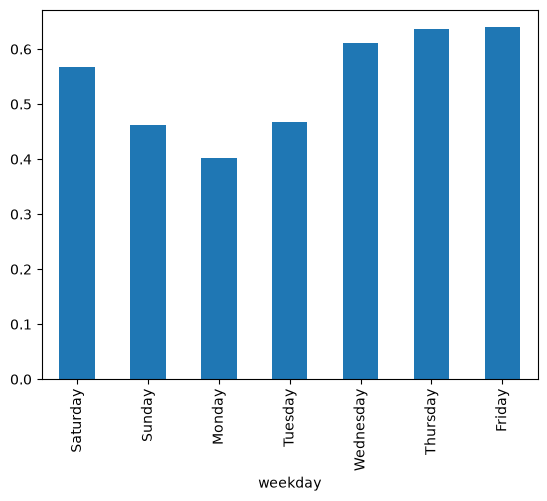

In [130]:
weekday_fraud.plot(kind="bar")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> نرخ تقلب در <strong>پنج‌شنبه</strong> و <strong>جمعه</strong> (حدود 0.64٪) از بقیه روزها بیشتر است و چهارشنبه هم نزدیک به آن‌هاست (0.61٪). کمترین نرخ مال <strong>دوشنبه</strong> (0.40٪) است. تفاوت روزها نسبتاً کم است. جالب اینکه یکشنبه و دوشنبه بیشترین <strong>تعداد</strong> تراکنش را داشتند ولی کمترین <strong>نرخ</strong> تقلب را دارند.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">29. نرخ تقلب در هر ماه (<code dir="ltr">month</code>)</h3>
<p dir="rtl" align="right">نرخ تقلب هر ماه را با ماه‌های دیگر مقایسه می‌کنیم. هر ماه داده دو سال (2019 و 2020) را با هم دارد.</p>
</div>

In [131]:
month_fraud = df.groupby("month")["is_fraud"].mean() * 100
month_fraud

month
1     0.810679
2     0.873465
3     0.652345
4     0.502334
5     0.636596
6     0.472195
7     0.378094
8     0.452538
9     0.540714
10    0.606780
11    0.476736
12    0.302924
Name: is_fraud, dtype: float64

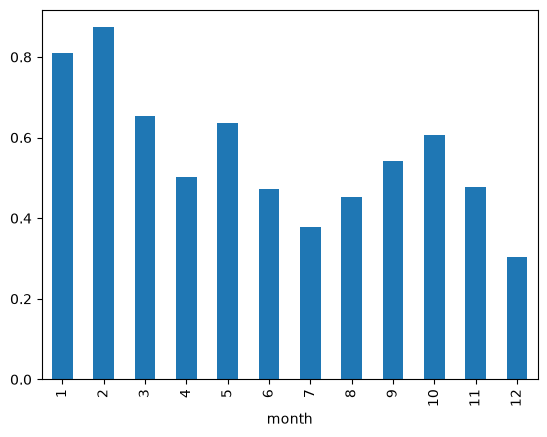

In [132]:
month_fraud.plot(kind="bar")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> بیشترین نرخ تقلب در <strong>ماه 2</strong> (0.87٪) است (ماه 1 هم با 0.81٪ بالاست). از ماه 2 تا ماه 7 نرخ تقریباً نزولی است. از ماه 7 تا 10 کمی بالا می‌رود ولی باز هم از ماه 2 کمتر است و کمترین نرخ مال <strong>ماه 12</strong> (0.30٪) است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">30. نرخ تقلب بر اساس جنسیت (<code dir="ltr">gender</code>)</h3>
</div>

In [133]:
gender_fraud = df.groupby("gender")["is_fraud"].mean() * 100
gender_fraud

gender
F    0.482779
M    0.567305
Name: is_fraud, dtype: float64

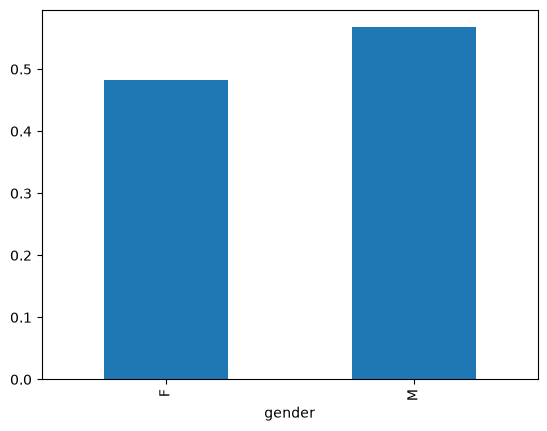

In [134]:
gender_fraud.plot(kind="bar")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> نرخ تقلب بین زنان (0.48٪) و مردان (0.57٪) خیلی فرق ندارد، ولی نرخ مردان کمی بیشتر است با اینکه مردان تعداد تراکنش کمتری ازازنان داشتند اما مردان نرخ تقلب بالاتری از زنان دارند.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">31. نرخ تقلب در هر گروه سنی (<code dir="ltr">age group</code>)</h3>
</div>

In [135]:
age_group_fraud = df.groupby("age group")["is_fraud"].mean() * 100
age_group_fraud

age group
<=25     0.559913
26-35    0.432206
36-45    0.393412
46-55    0.530964
56-65    0.676501
66+      0.670086
Name: is_fraud, dtype: float64

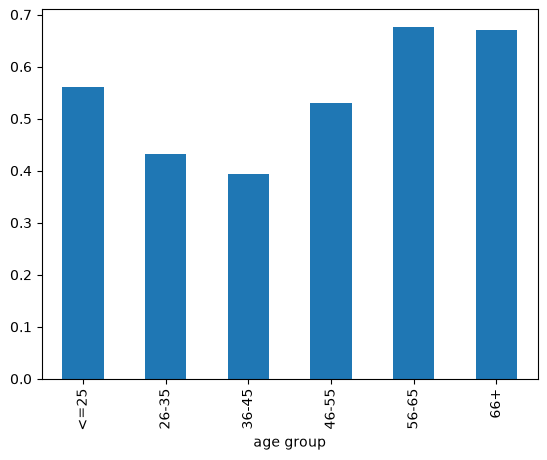

In [136]:
age_group_fraud.plot(kind="bar")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> نرخ تقلب از گروه <code dir="ltr">&lt;=25</code> (0.56٪) تا گروه <code dir="ltr">36-45</code> (0.39٪، کمترین نرخ) نزولی است. از گروه 46 سال به بالا دوباره صعودی می‌شود و در گروه‌های <code dir="ltr">56-65</code> (0.68٪) و <code dir="ltr">66+</code> (0.67٪) به بیشترین مقدار خود می‌رسد. یعنی افراد مسن‌تر نرخ تقلب بالاتری دارند و تفاوت گروه‌ها کم است (بین 0.39٪ تا 0.68٪).</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">32. نرخ تقلب در هر ایالت (<code dir="ltr">state</code>)</h3>
<p dir="rtl" align="right">با <code dir="ltr">agg(["count", "sum", "mean"])</code> برای هر ایالت سه عدد می‌گیریم: <code dir="ltr">count</code> تعداد تراکنش، <code dir="ltr">sum</code> تعداد تراکنش تقلبی و <code dir="ltr">mean</code> نرخ تقلب (که در 100 ضرب شده است).</p>
</div>

In [137]:
state_stats = df.groupby("state")["is_fraud"].agg(["count", "sum", "mean"])
state_stats["mean"] = state_stats["mean"] * 100
state_stats.sort_values("mean", ascending=False).head(10)

,count,sum,mean
state,,,
DE,9,9,100.000000
RI,745,15,2.013423
AK,2963,50,1.687479
OR,26408,197,0.745986
NH,11727,79,0.673659
VA,41756,273,0.653798
TN,24913,159,0.638221
NE,34425,216,0.627451
MN,45433,280,0.616292


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right">ایالت <code dir="ltr">DE</code> فقط 9 تراکنش دارد و هر 9 تای آن تقلبی است، پس نرخش 100٪ شده است. با تعداد نمونه این‌قدر کم، نرخ قابل‌اعتماد نیست. با <code dir="ltr">(state_stats["count"] &lt; 1000).sum()</code> تعداد ایالت‌هایی را می‌شماریم که کمتر از 1000 تراکنش دارند و آن‌ها را از نمودار کنار می‌گذاریم.</p>
</div>

In [138]:
(state_stats["count"] < 1000).sum()

np.int64(2)

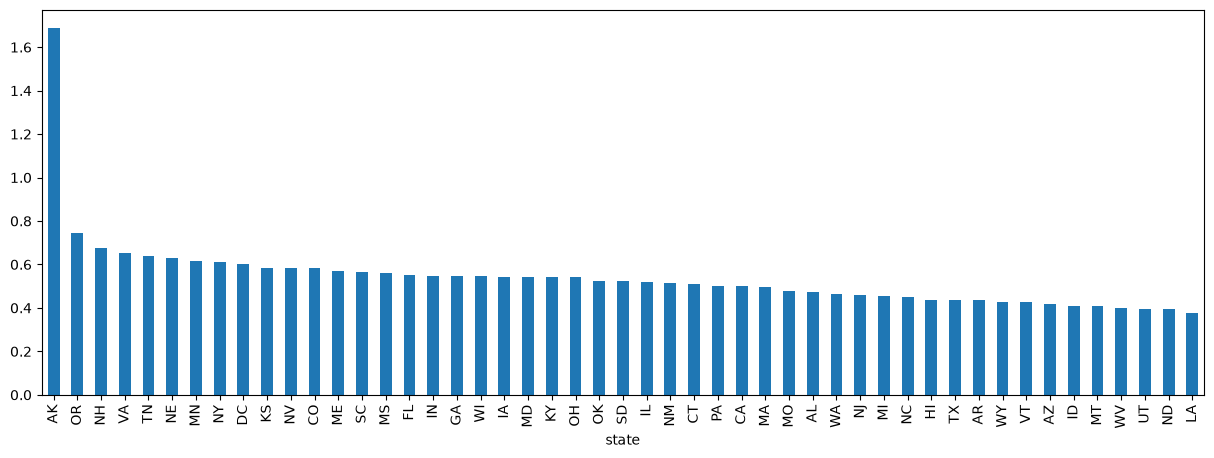

In [139]:
state_stats_filtered = state_stats[state_stats["count"] >= 1000]
state_stats_filtered["mean"].sort_values(ascending=False).plot(kind="bar", figsize=(15, 5))
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> دو ایالت کمتر از 1000 تراکنش داشتند (<code dir="ltr">DE</code> با 9 و <code dir="ltr">RI</code> با 745 تراکنش) و از نمودار کنار گذاشته شدند، چون نرخشان ناپایدار است و مقیاس نمودار را خراب می‌کند. بقیه ایالت‌ها بهتر دیده می‌شوند. بر اساس نمودار، نرخ تقلب در ایالت <strong>AK</strong> (حدود 1.69٪) از بقیه بیشتر است. بقیه ایالت‌ها با شیب کمی کاهش پیدا می‌کنند و نرخشان خیلی کمتر از AK است (مثلاً <code dir="ltr">OR</code> 0.75٪ و <code dir="ltr">NY</code> 0.61٪).</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">33. مقایسه مبلغ تراکنش‌های عادی و تقلبی (<code dir="ltr">amt</code>)</h3>
<p dir="rtl" align="right">اول میانگین، میانه و چند عدد دیگر را برای دو گروه می‌گیریم، بعد چارک‌ها و بعد باکس‌پلات و هیستوگرام دو گروه را می‌کشیم.</p>
</div>

In [140]:
df.groupby("is_fraud")["amt"].agg(["count", "mean", "median", "std", "min", "max"])

,count,mean,median,std,min,max
is_fraud,,,,,,
0,1842743,67.651276,47.240002,153.548111,1.00,28948.900391
1,9651,530.661438,390.000000,391.028870,1.06,1376.040039


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> میانگین تراکنش‌های عادی <strong>67.65</strong> و تقلبی <strong>530.66</strong> است. میانه تراکنش‌های عادی <strong>47.24</strong> و تقلبی <strong>390</strong> است. میانگین و میانه هر دو نشان می‌دهند مبلغ تراکنش‌های تقلبی خیلی بالاتر است. فاصله میانگین از میانه در هر گروه به‌خاطر چولگی شدید به راست داده است. بیشترین مبلغ تقلبی 1,376 دلار است، در حالی که در تراکنش‌های عادی به 28,949 دلار می‌رسد.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right">چارک‌ها را برای دو گروه جدا می‌بینیم. باکس‌پلات دو گروه کنار هم رسم شده (بدون نقطه‌های پرت) و بعد هیستوگرام روی بازه 0 تا 1000 دلار. در هیستوگرام از <code dir="ltr">density=True</code> استفاده شده تا به‌جای تعداد، <strong>شکل توزیع</strong> مقایسه شود (چون تعداد دو گروه خیلی فرق دارد).</p>
</div>

In [141]:
df.groupby("is_fraud")["amt"].quantile([0.25, 0.5, 0.75, 0.95]).unstack()

,0.25,0.50,0.75,0.95
is_fraud,,,,
0,9.610000,47.240002,82.559998,189.589996
1,240.075005,390.000000,902.364990,1084.090027


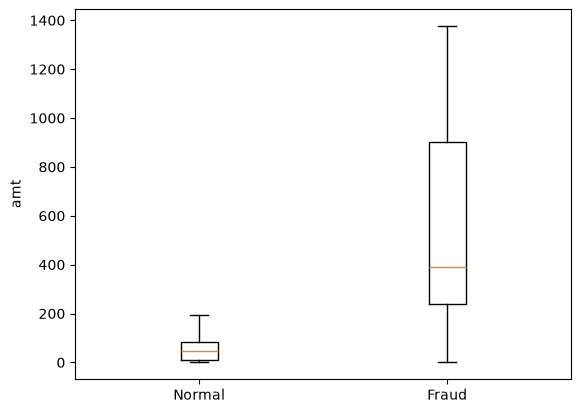

In [142]:
amt_normal = df.loc[df["is_fraud"] == 0, "amt"]
amt_fraud = df.loc[df["is_fraud"] == 1, "amt"]

plt.boxplot([amt_normal, amt_fraud], tick_labels=["Normal", "Fraud"], showfliers=False)
plt.ylabel("amt")
plt.show()

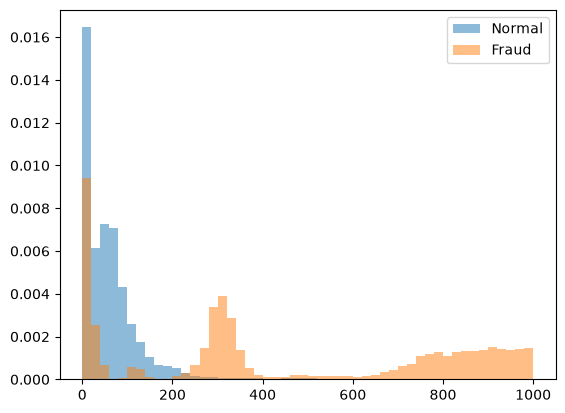

In [143]:
plt.hist(amt_normal, bins=50, range=(0, 1000), alpha=0.5, density=True, label="Normal")
plt.hist(amt_fraud, bins=50, range=(0, 1000), alpha=0.5, density=True, label="Fraud")
plt.legend()
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>چارک‌ها:</strong> چارک اول تراکنش‌های تقلبی (240 دلار) از صدک 95 تراکنش‌های عادی (حدود 190 دلار) هم بزرگ‌تر است. یعنی بیش از 75٪ تراکنش‌های تقلبی از 95٪ تراکنش‌های عادی بزرگ‌ترند.</li>
<li dir="rtl" align="right"><strong>باکس‌پلات:</strong> میانه گروه تقلبی بالاتر است و جعبه‌های دو گروه هم‌پوشانی ندارند.</li>
<li dir="rtl" align="right"><strong>هیستوگرام:</strong> تراکنش‌های عادی بیشتر در مبلغ‌های پایین (کمتر از 200 دلار) متمرکزند. تراکنش‌های تقلبی در مبلغ‌های کم هم وجود دارند ولی سهم آن‌ها در مبلغ‌های متوسط و بالا بیشتر است.</li>
<li dir="rtl" align="right"><strong>چولگی:</strong> چولگی داده بیشتر از مبلغ‌های خیلی بالای تراکنش‌های <strong>عادی</strong> می‌آید، چون بیشترین مبلغ تقلبی فقط 1,376 دلار است و اکثریت تراکنش‌ها مبلغ کمی دارند.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right">در آخر درصد تراکنش‌های بالای 200 دلار را در هر گروه می‌بینیم.</p>
</div>

In [144]:
(df["amt"] > 200).groupby(df["is_fraud"]).mean() * 100

is_fraud
0     4.339075
1    75.795254
Name: amt, dtype: float64

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> فقط <strong>4.34٪</strong> تراکنش‌های عادی بالای 200 دلار هستند، ولی در گروه تقلبی <strong>75.80٪</strong>. یعنی تراکنش‌های بالای 200 دلار در گروه تقلبی خیلی بیشتر از گروه عادی است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">34. ماتریس همبستگی</h3>
<p dir="rtl" align="right"><strong>همبستگی</strong> عددی بین <strong>-1 و 1</strong> است که نشان می‌دهد دو ستون عددی چقدر با هم بالا و پایین می‌روند: 1 یعنی رابطه مستقیم، 0 یعنی رابطه خطی ندارند و -1 یعنی رابطه معکوس. با <code dir="ltr">corr()</code> برای هر جفت ستون یک عدد حساب می‌شود. ستون‌های بررسی‌شده <code dir="ltr">amt</code>، <code dir="ltr">age</code>، <code dir="ltr">city_pop</code>، <code dir="ltr">hour</code>، <code dir="ltr">month</code> و <code dir="ltr">is_fraud</code> هستند.</p>
</div>

In [145]:
num_cols = ["amt", "age", "city_pop", "hour", "month", "is_fraud"]
corr = df[num_cols].corr()
corr

,amt,age,city_pop,hour,month,is_fraud
amt,1.000000,-0.010735,0.004921,-0.024891,-0.002593,0.209308
age,-0.010735,1.000000,-0.092219,-0.173163,0.016633,0.010637
city_pop,0.004921,-0.092219,1.000000,0.019949,-0.000510,0.000325
hour,-0.024891,-0.173163,0.019949,1.000000,-0.000986,0.013196
month,-0.002593,0.016633,-0.000510,-0.000986,1.000000,-0.016417
is_fraud,0.209308,0.010637,0.000325,0.013196,-0.016417,1.000000


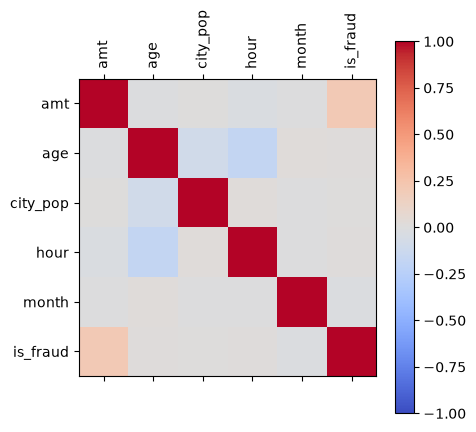

In [169]:
plt.matshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(6), num_cols, rotation=90)
plt.yticks(range(6), num_cols)
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><code dir="ltr">amt</code> بیشترین همبستگی را با <code dir="ltr">is_fraud</code> دارد (<strong>0.21</strong>) و مثبت است، یعنی هرچه مبلغ بیشتر باشد تقلب بیشتر است. این مقدار ضعیف است ولی از بقیه خیلی بیشتر است.</li>
<li dir="rtl" align="right">همبستگی بقیه ستون‌ها با تقلب خیلی کوچک است (کمتر از 0.02). دلیلش این است که تقلب فقط 0.52٪ داده است، پس همبستگی‌ها کوچک می‌شوند و عدد کوچک یعنی رابطه خطی خیلی ضعیف.</li>
<li dir="rtl" align="right"><strong>نکته:</strong> <code dir="ltr">hour</code> همبستگی تقریباً صفر (0.013) دارد، در حالی که نرخ تقلب در ساعت‌ها خیلی فرق می‌کند. دلیلش این است که رابطه ساعت با تقلب <strong>خطی نیست</strong> (تقلب شب‌ها زیاد است و همبستگی فقط رابطه خطی را می‌سنجد).</li>
<li dir="rtl" align="right">در نمودار هم رابطه <code dir="ltr">amt</code> با <code dir="ltr">is_fraud</code> از بقیه پررنگ‌تر است. خانه‌های قطری (رابطه هر ستون با خودش) همیشه 1 و پررنگ‌ترین‌اند.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h2 dir="rtl" align="right">بخش چهارم: تحلیل چندمتغیره (Multivariate Analysis)</h2>
<p dir="rtl" align="right">در این بخش چند ستون را هم‌زمان بررسی می‌کنیم.</p>
<h3 dir="rtl" align="right">35. نرخ تقلب بر اساس دسته خرید و جنسیت</h3>
</div>

In [147]:
rate_cat_gender = (df.groupby(["category", "gender"])["is_fraud"].mean() * 100).unstack()
rate_cat_gender

gender,F,M
category,,
entertainment,0.270522,0.162174
food_dining,0.233986,0.069926
gas_transport,0.307811,0.537654
grocery_net,0.209910,0.345285
grocery_pos,1.063932,1.490018
health_fitness,0.242763,0.048375
home,0.257335,0.031483
kids_pets,0.272343,0.082210
misc_net,0.992716,1.705321


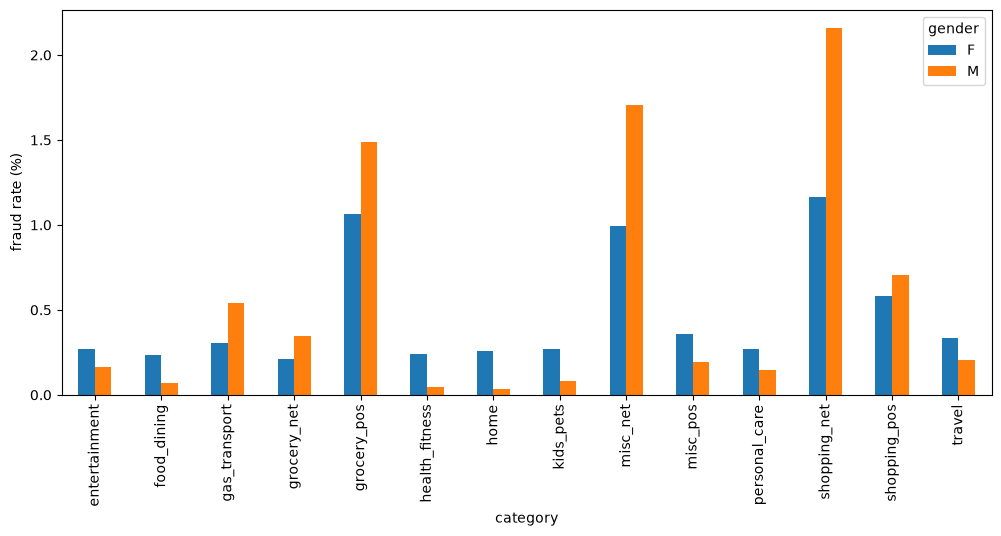

In [148]:
rate_cat_gender.plot(kind="bar", figsize=(12, 5))
plt.ylabel("fraud rate (%)")
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">در 8 دسته (<code dir="ltr">entertainment</code>، <code dir="ltr">food_dining</code>، <code dir="ltr">health_fitness</code>، <code dir="ltr">home</code>، <code dir="ltr">kids_pets</code>، <code dir="ltr">misc_pos</code>، <code dir="ltr">personal_care</code> و <code dir="ltr">travel</code>) نرخ تقلب زنان بیشتر است و در 6 دسته (<code dir="ltr">gas_transport</code>، <code dir="ltr">grocery_net</code>، <code dir="ltr">grocery_pos</code>، <code dir="ltr">misc_net</code>، <code dir="ltr">shopping_net</code> و <code dir="ltr">shopping_pos</code>) نرخ مردان بیشتر است.</li>
<li dir="rtl" align="right">دسته‌های پرخطر (<code dir="ltr">shopping_net</code>، <code dir="ltr">misc_net</code>، <code dir="ltr">grocery_pos</code>) همگی دسته‌هایی هستند که نرخ <strong>مردان</strong> در آن‌ها بیشتر است. در بیشتر دسته‌های کم‌خطر نرخ زنان بیشتر است.</li>
<li dir="rtl" align="right">بالاترین نرخ تقلب مال <code dir="ltr">shopping_net</code> برای <strong>مردان</strong> است (2.16٪).</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">36. میانه مبلغ در هر ساعت، برای تراکنش عادی و تقلبی</h3>
<p dir="rtl" align="right">به‌جای میانگین از <strong>میانه</strong> استفاده می‌کنیم، چون <code dir="ltr">amt</code> چولگی دارد.</p>
</div>

In [149]:
hour_amt = df.groupby(["hour", "is_fraud"])["amt"].median().unstack()
print(hour_amt)

is_fraud          0           1
hour                           
0         61.099998  300.369995
1         61.439999  308.519989
2         62.060001  311.709991
3         61.419998  308.049988
4         61.279999  308.549988
5         61.735001  306.215027
6         61.514999  297.230011
7         61.410000  305.540009
8         61.540001  308.320007
9         61.470001  293.089996
10        61.029999  313.039978
11        61.759998  298.209991
12        33.810001  795.204956
13        33.610001  792.285034
14        33.860001  883.015015
15        33.619999  778.794983
16        33.520000  765.929993
17        33.980000  793.299988
18        33.919998  831.000000
19        33.560001  760.289978
20        34.049999  860.645020
21        33.930000  817.940002
22        33.470001  818.450012
23        33.580002  797.920044


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong> میانه مبلغ تراکنش‌های تقلبی در <strong>همه</strong> ساعت‌ها بیشتر از عادی است. از ساعت 0 تا 11 میانه عادی حدود 61 و تقلبی حدود 300 دلار است. از ساعت <strong>12 تا 23</strong> میانه عادی به حدود 34 دلار می‌رسد و تقلبی به حدود 800 دلار می‌رسد، یعنی فاصله بیشتر می‌شود. این تغییر ناگهانی در ساعت 12 با همان پله‌ای که در تعداد تراکنش‌ها دیدیم هم‌خوان است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">37. نرخ تقلب بر اساس گروه سنی و جنسیت</h3>
</div>

In [150]:
rate_age_gender = (df.groupby(["age group", "gender"])["is_fraud"].mean() * 100).unstack()
rate_age_gender

gender,F,M
age group,,
<=25,0.632590,0.482927
26-35,0.368943,0.524177
36-45,0.321679,0.472642
46-55,0.459380,0.620143
56-65,0.708651,0.644777
66+,0.643636,0.705299


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>تحلیل:</strong></p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">گروه <code dir="ltr">&lt;=25</code>: نرخ تقلب زنان بیشتر است.</li>
<li dir="rtl" align="right">گروه‌های <strong>26 تا 55</strong> (<code dir="ltr">26-35</code>، <code dir="ltr">36-45</code> و <code dir="ltr">46-55</code>): نرخ مردان بیشتر است.</li>
<li dir="rtl" align="right">گروه <code dir="ltr">56-65</code>: نرخ زنان بیشتر است.</li>
<li dir="rtl" align="right">گروه <code dir="ltr">66+</code>: نرخ مردان بیشتر است.</li>
<li dir="rtl" align="right">بیشترین نرخ مال زنان گروه <code dir="ltr">56-65</code> (0.71٪) و مردان گروه <code dir="ltr">66+</code> (0.71٪) است.</li>
</ul>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h2 dir="rtl" align="right">بخش پنجم: آزمون‌های آماری</h2>
<h3 dir="rtl" align="right">38. مقدمه</h3>
<p dir="rtl" align="right">در بخش دومتغیره دیدیم مبلغ تراکنش‌های تقلبی خیلی بالاتر است. حالا با آزمون آماری بررسی می‌کنیم که این تفاوت <strong>معنی‌دار</strong> است یا نه. روش کار در هر آزمون این است:</p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>فرضیه صفر (H₀):</strong> تفاوتی بین دو گروه نیست.</li>
<li dir="rtl" align="right"><strong>فرضیه جایگزین (H₁):</strong> تفاوت وجود دارد.</li>
<li dir="rtl" align="right"><strong>سطح معنی‌داری (α):</strong> 0.05.</li>
<li dir="rtl" align="right"><strong>p-value:</strong> احتمال دیدن چنین نتیجه‌ای اگر H₀ درست باشد. اگر <strong>p-value &lt; 0.05</strong> باشد، H₀ را رد می‌کنیم و می‌گوییم تفاوت معنی‌دار است.</li>
</ul>
<p dir="rtl" align="right"><strong>چرا t-test نزدیم؟</strong> تست t فرض می‌کند داده نرمال است، ولی مبلغ تراکنش چولگی شدید دارد و نرمال نیست. پس از آزمون‌های <strong>ناپارامتری</strong> (بدون فرض نرمال) استفاده می‌کنیم.</p>
<p dir="rtl" align="right">دو گروه ما: تراکنش‌های عادی (1,842,743 مورد) و تقلبی (9,651 مورد).</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">39. آزمون Mann-Whitney U</h3>
<p dir="rtl" align="right"><strong>سؤال:</strong> آیا توزیع مبلغ تراکنش‌های عادی و تقلبی با هم تفاوت دارد؟</p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>H₀:</strong> توزیع مبلغ دو گروه یکسان است.</li>
<li dir="rtl" align="right"><strong>H₁:</strong> توزیع مبلغ دو گروه متفاوت است.</li>
</ul>
<p dir="rtl" align="right">در کد، مبلغ هر گروه را جدا می‌کنیم و با <code dir="ltr">mannwhitneyu(..., alternative="two-sided")</code> آزمون دوطرفه را اجرا می‌کنیم. خروجی آماره U و p-value است.</p>
</div>

In [151]:
normal_mw = df.loc[df["is_fraud"] == 0, "amt"]
fraud_mw = df.loc[df["is_fraud"] == 1, "amt"]

mw_statistic , mw_p_value = mannwhitneyu(normal_mw, fraud_mw, alternative="two-sided")

print("U-statistics", mw_statistic)
print("P-value", mw_p_value)

U-statistics 2.947154e+09
P-value 0.0


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>نتیجه:</strong> p-value برابر <strong>0</strong> شد (در واقع عددی آن‌قدر کوچک که پایتون صفر نشان می‌دهد). چون p-value &lt; 0.05، <strong>H₀ رد می‌شود</strong> و توزیع مبلغ دو گروه یکسان نیست. با توجه به میانه‌ها (390 دلار برای تقلبی و 47 دلار برای عادی)، مبلغ تراکنش‌های تقلبی بزرگ‌تر است.</p>
<p dir="rtl" align="right">از روی آماره U هم می‌شود فهمید که اندازه این تفاوت بزرگ است: اگر یک تراکنش عادی و یک تراکنش تقلبی را تصادفی انتخاب کنیم، حدود <strong>83٪</strong> احتمال دارد مبلغ تراکنش تقلبی بیشتر باشد.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">40. آزمون Kolmogorov-Smirnov (KS)</h3>
<p dir="rtl" align="right"><strong>سؤال:</strong> آیا توزیع مبلغ (<code dir="ltr">amt</code>) در تراکنش‌های عادی و تقلبی تفاوت دارد؟ این آزمون برخلاف قبلی به <strong>کل شکل توزیع</strong> نگاه می‌کند.</p>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>H₀:</strong> مبلغ دو گروه از یک توزیع آمده‌اند.</li>
<li dir="rtl" align="right"><strong>H₁:</strong> مبلغ دو گروه از توزیع‌های متفاوتی آمده‌اند.</li>
</ul>
<p dir="rtl" align="right">با <code dir="ltr">ks_2samp</code> آزمون دو نمونه‌ای اجرا می‌شود. آماره KS بیشترین فاصله بین نمودار توزیع تجمعی دو گروه است و عددی بین 0 و 1 دارد.</p>
</div>

In [152]:
normal_ks = df.loc[df["is_fraud"] == 0, "amt"]
fraud_ks = df.loc[df["is_fraud"] == 1, "amt"]

ks_statistic , ks_p_value = ks_2samp(normal_ks, fraud_ks)

print("Ks2-statistics", ks_statistic)
print("P-value", ks_p_value)

Ks2-statistics 0.72380304
P-value 0.0


<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<p dir="rtl" align="right"><strong>نتیجه:</strong> آماره KS برابر <strong>0.72</strong> است (فاصله خیلی زیاد بین دو توزیع) و p-value برابر <strong>0</strong> است. چون p-value &lt; 0.05، <strong>H₀ رد می‌شود</strong> و توزیع مبلغ تراکنش‌های عادی و تقلبی متفاوت است. این نتیجه با آزمون Mann-Whitney هم‌جهت است.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h3 dir="rtl" align="right">41. جمع‌بندی آزمون‌ها</h3>
<p dir="rtl" align="right">هر دو آزمون نشان دادند مبلغ تراکنش‌های عادی و تقلبی تفاوت <strong>معنی‌داری</strong> دارد و مبلغ تراکنش‌های تقلبی بیشتر است.</p>
<p dir="rtl" align="right">نکته: p-value فقط می‌گوید تفاوت وجود دارد، نه اینکه چقدر بزرگ است. اندازه تفاوت را از میانه‌ها (390 در برابر 47) و آماره KS (0.72) می‌فهمیم.</p>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right;">
<h2 dir="rtl" align="right">بخش ششم: نتیجه‌گیری نهایی</h2>
<h3 dir="rtl" align="right">42. یافته‌های اصلی</h3>
<ul dir="rtl" align="right">
<li dir="rtl" align="right"><strong>داده:</strong> حدود 1.85 میلیون تراکنش، فقط <strong>0.52٪ تقلبی</strong> (داده نامتوازن)، بدون مقدار گمشده و ردیف تکراری. به همین دلیل گروه‌ها را با <strong>نرخ تقلب</strong> مقایسه کردیم.</li>
<li dir="rtl" align="right"><strong>ساعت:</strong> قوی‌ترین الگو مربوط به زمان است. نرخ تقلب در بازه <strong>22 تا 4 صبح</strong> بالاست (حدود 1.3٪ در ساعت 0 تا 3 و حدود 2.6٪ در ساعت 22 و 23) و در بقیه روز حدود 0.1٪ است.</li>
<li dir="rtl" align="right"><strong>مبلغ:</strong> مبلغ تراکنش‌های تقلبی خیلی بالاتر است (میانه 390 در برابر 47 دلار). 75.8٪ تراکنش‌های تقلبی بالای 200 دلارند، در حالی که فقط 4.3٪ تراکنش‌های عادی. آزمون‌های Mann-Whitney و KS هم این تفاوت را معنی‌دار نشان دادند. در ماتریس همبستگی هم <code dir="ltr">amt</code> بیشترین رابطه را با تقلب دارد (0.21).</li>
<li dir="rtl" align="right"><strong>دسته خرید:</strong> بیشترین نرخ تقلب در <code dir="ltr">shopping_net</code> (1.59٪)، <code dir="ltr">misc_net</code> (1.30٪) و <code dir="ltr">grocery_pos</code> (1.26٪) است.</li>
<li dir="rtl" align="right"><strong>جنسیت و سن:</strong> مردان (0.57٪) کمی بیشتر از زنان (0.48٪) و افراد مسن (56 سال به بالا) و گروه <code dir="ltr">&lt;=25</code> نرخ بالاتری دارند. در دسته‌های پرخطر نرخ مردان بیشتر است. تفاوت‌ها کم است.</li>
<li dir="rtl" align="right"><strong>روز هفته و ماه:</strong> تفاوت‌ها کم است. نرخ تقلب در پنج‌شنبه و جمعه بیشتر و در دوشنبه کمتر است و بیشترین نرخ ماهانه در ماه 2 و کمترین در ماه 12 است.</li>
<li dir="rtl" align="right"><strong>ایالت:</strong> <code dir="ltr">AK</code> نرخ بالاتری از بقیه دارد (بعد از کنار گذاشتن ایالت‌های کم‌تراکنش).</li>
</ul>
<h3 dir="rtl" align="right">محدودیت‌ها</h3>
<ul dir="rtl" align="right">
<li dir="rtl" align="right">داده <strong>شبیه‌سازی‌شده</strong> است. بعضی الگوها (مثل پله ناگهانی ساعت 12) احتمالاً از نحوه شبیه‌سازی می‌آیند و لزوماً در دنیای واقعی دیده نمی‌شوند.</li>
<li dir="rtl" align="right">نامتوازن بودن داده باعث می‌شود نرخ گروه‌های کوچک ناپایدار باشد (مثل ایالت <code dir="ltr">DE</code>).</li>
<li dir="rtl" align="right">تحلیل ماه‌ها داده دو سال را با هم ترکیب می‌کند.</li>
<li dir="rtl" align="right">همبستگی و تفاوت بین گروه‌ها <strong>علّیت</strong> را اثبات نمی‌کند و فقط الگوها را نشان می‌دهد.</li>
</ul>
<h3 dir="rtl" align="right">پیشنهاد</h3>
<p dir="rtl" align="right">برای شناسایی تقلب، بیشترین توجه باید روی <strong>تراکنش‌های شبانه (22 تا 4 صبح)</strong> و <strong>تراکنش‌های بالای 200 دلار</strong>، به‌خصوص در دسته‌های <code dir="ltr">shopping_net</code>، <code dir="ltr">misc_net</code> و <code dir="ltr">grocery_pos</code> باشد.</p>
</div>